# Where noise must enter to change the model's algorithm

**Artifact:** `art_Cx9JOh8soBw7` (experiment, iteration 4). **Model:** Qwen3-8B (rev `b968826d`, thinking off, T = 1.0, FP8 W8A8).

## The question

Adding *isotropic random noise* to the residual stream of Qwen3-8B can make it write a **different correct algorithm** for the same coding task (for example, quickselect instead of a full sort). This experiment asks **where** the noise has to enter for that to happen. The same random displacement, at the same per-position dose, is written into six *sites*:

| Site | Blocks | Positions |
|---|---|---|
| **S0** | 12-23 | the task-specification tokens |
| S1 | 12-23 | the read position R (last prompt token) |
| S2 | 12-23 | the condition sentence |
| S3 | 12-23 | generated tokens 1-32 |
| S4 | 0-11 | the task-specification tokens |
| S5 | 24-35 | the task-specification tokens |

The dose is `alpha` × a *ban unit*: the per-position size of the shift that a real prompt ban ("do not use X") causes at that site. Each site runs at alpha 1, 2 and 4. There are six tasks: T03 k-th smallest, T05 two sum, T06 find duplicate, T10 connected components, T1 grid path and T2 weighted shortest path. Every program is run against hidden tests and labelled with the algorithm it implements.

**Common random numbers (CRN).** Each slot (task, template, k) uses **one** random direction and **one** stream of token uniforms, and every arm shares them. So comparing two sites on the same slot is an *exact paired flip*, not a comparison of independent samples.

**Pricing a site.** For each site, a *randomisation hull* mixes the twin (alpha 0) with alpha 1/2/4. It trades **correct-only diversity of algorithms** (rarefied Hill-1 at depth 25) against **pass-rate cost**. `H5` is the best diversity reachable within a pass-rate cost of 0.05.

## Full-run results (4,510 programs)

- **C1-site = PARTIAL.** S0 has the best H5 on 3 of 6 tasks (the pre-registered threshold was 4).
- **Inert sites.** S1 and S2 never change the algorithm (0/526 and 0/527 correct off-default programs), and S5 almost never does (6/521).
- **The effect is tied to the site.** S1 moves the downstream state at R as far as S0 does, yet S0 keeps a +2.15 logit advantage at matched downstream displacement.
- **Alpha 8** erases the task: the pass rate is 0 on all six tasks.
- **The TOP5 plan push** (a push along the "survivors minus top-5 algorithms" direction) never moves the model off BFS.
- **No novel algorithms:** 0 among 3,555 correct programs.

## What this notebook runs

The original `method.py` is an **orchestrator**: each sub-command launches one stage script in `src/`. The GPU stage cannot run on Colab in 10 minutes: it samples 4,510 programs from Qwen3-8B on a 16 GB FP8 GPU, which takes about 2.5 h. Nor can the stages that call LLM judges. This notebook re-runs **every CPU stage** of the pipeline on the *recorded, labelled programs* of a curated subset:

1. **Method mechanics on CPU:** the CRN directions and token uniforms, the inverse-CDF sampler and the displacement-targeted hook (`src/gpu_main.py`, `src/engine.py`, `src/hooks.py`).
2. **The randomisation hull and the frozen C1-site decision rule** (`src/hull.py`).
3. **CPU unit tests T1-T5** (`tests/test_cpu.py`).
4. **The STEP 11 analysis** (`src/analysis.py`): cells, hull + bootstrap, C1-site, failure modes, paired flips, transmission, pooled model, boundary and the C3d plan-site geometry.
5. **Figures 1-7** (`src/figures.py`).
6. **A summary**: demo-subset results next to the full-run results, and plots of the activation-space geometry.

**Demo data** (`mini_demo_data.json`) holds 90 CRN slots: 6 tasks × 5 templates × k 0-2, with every arm sampled on each slot. That is 2,025 labelled programs, or N = 15 per cell instead of the full run's 30, so the numbers are noisier. The full-run values are printed alongside them for comparison.

In [1]:
%%capture
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, pandas, scipy, scikit-learn, statsmodels, matplotlib, torch — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'statsmodels==0.14.6',
         'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

# loguru, ripser — NOT on Colab, always install (after the block above, so pip's conflict check never flags
# ripser's optional extras; ripser imports persim only lazily for plotting, and --no-deps keeps numpy/scipy/sklearn untouched)
_pip('loguru==0.7.3')
_pip('--no-deps', 'ripser==0.6.15')

In [2]:
from __future__ import annotations

# ---- original imports of src/cfg.py, src/hooks.py, src/hull.py, src/analysis.py, src/figures.py, tests/test_cpu.py ----
import ast
import glob
import hashlib
import itertools
import json
import math
import multiprocessing as mp
import os
import resource
import sys
import time
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Iterable

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from loguru import logger

import warnings

# notebook: silence known, benign warnings that the original run also logged (all-NaN bootstrap columns in the
# hull summary; perfect separation in some transmission logit fits)
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", category=RuntimeWarning, module="statsmodels")
warnings.filterwarnings("ignore", message="Maximum Likelihood optimization failed")

# notebook: figures.py called matplotlib.use("Agg") (save-only); here the figures are saved AND shown inline
%matplotlib inline

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-4/experiment-20/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

_ex = data["datasets"][0]["examples"]
print(data["metadata"]["title"])
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(_ex)} CRN slots, "
      f"{sum(len(e['metadata_rows']) for e in _ex)} labelled programs (all arms on every slot)")
print("first slot:", {k: v for k, v in _ex[0].items() if k.startswith(("output", "metadata_t", "metadata_k", "predict_S0"))})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where noise must enter to change the model's algorithm
dataset 'site_grid': 90 CRN slots, 2025 labelled programs (all arms on every slot)
first slot: {'output': 'full_sort|pass', 'metadata_task': 'T03', 'metadata_template': 'W1', 'metadata_k': 0, 'predict_S0_a1': 'quickselect|pass', 'predict_S0_a2': 'counting_sort|fail', 'predict_S0_a4': 'full_sort|fail'}


## Config

Every knob that sets the cost of this demo lives here. The comment on each line gives the value the original full run used.

- **Already at the full-run settings:** `HULL_N_DRAWS`, `HULL_STEP` and `RIPSER_NULL_DRAWS`, and `DEMO_KS` uses every slot the demo data holds.
- **Scaled down:** `BOOT_B` is 100 instead of 2,000.

With these values the notebook ran in about 3 minutes in a clean local environment:

- installs: about 25-55 s;
- hull point estimates: about 17 s;
- 100 bootstrap replicates: about 95 s;
- everything else: about 15 s.

To scale further, note that each extra 100 bootstrap replicates costs about 1.5 minutes on one core. `DEMO_KS` cannot go beyond `[0, 1, 2]`, because the demo data holds only those slots; the full grid uses k 0-5. For the minimum smoke test, use `DEMO_KS = [0]`, `HULL_N_DRAWS = 200`, `HULL_STEP = 0.1`, `BOOT_B = 0` and `RIPSER_NULL_DRAWS = 2`, which runs in under a minute.

In [5]:
# ---- demo scale (the value used by the original full run is given in each comment) ----
DEMO_KS = [0, 1, 2]      # CRN slots k read from the demo data (all it holds -> N = 15 per cell); original grid: k 0-5 (N = 30)
HULL_N_DRAWS = 1000      # CRN draws per hull point estimate (hull_all, _adjacent_interp); original: 1000
HULL_STEP = 0.05         # simplex-grid step of the hull mixture weights; original: 0.05
BOOT_B = 100             # template-stratified bootstrap replicates of the hull; original: 2000 (method.py default 1000)
BOOT_WORKERS = 1         # the notebook runs the bootstrap serially; original: 5 worker processes
RIPSER_NULL_DRAWS = 20   # coordinate-permutation null draws of the C3d H1-persistence check; original: 20

## The orchestrator `method.py` and where each stage goes

`method.py` is a thin driver: `uv run method.py <stage>` runs one stage script with `subprocess`. Every stage can be resumed. Its stage table, and where each stage appears in this notebook:

| Stage | What it does | In this notebook |
|---|---|---|
| `tests-cpu` | CPU unit tests T1-T5 (`tests/test_cpu.py`) | **Section 4**. T4 (screen byte-identity) is skipped because it needs the exp17/exp13 screen files. |
| `screen` | STEP 6 screen file (`src/screen.py`) | not run (it needs the earlier artifacts' inputs) |
| `gpu` | GPU prep (positions, units, C3d geometry), GPU tests U1-U7, engine check, staged sampling (`src/gpu_main.py`, `src/engine.py`) | not run: it needs Qwen3-8B in FP8 on a 16 GB GPU and takes about 2.5 h. **Its outputs are the demo data.** Its CRN and hook mechanics run on CPU in **Section 2**. |
| `commit0`, `commit1` | pre-registration hash chain (`src/prereg.py`, `src/commit.py`) | not run |
| `label`, `k7` | frozen labellers, with LLM judges on disagreement | not run: the labels are already in the demo data |
| `analysis` | STEP 11 (`src/analysis.py`, `src/hull.py`) | **Sections 3 and 5-12** |
| `audit`, `audit-summary`, `deps`, `rederive*`, `u4` | novelty audit (LLM judges), dependency use, re-derivations, GPU diagnostic | not run. Their full-run results are printed in the summary. |
| `figures` | fig1-fig7 (`src/figures.py`) | **Section 13** |
| `outputs` | `method_out.json` | not run (the demo data is a subset of it) |

The run order was: CPU tests → GPU prep → GPU tests → commit #0 → engine check → commit #1 (predictions, rules, hull code) → decisive sampling with the label worker → K=7 labels → analysis → audit → figures and outputs. This notebook follows that order for the CPU stages.

## 1. Frozen constants and utilities (`src/cfg.py`)

`cfg.py` holds every constant that was frozen before sampling: the model and decoding, the six tasks with their *default* algorithm (what the neutral prompt almost always produces), the sites with their blocks and positions, the doses, and the slot ranges.

Conventions used throughout:

- **Block l** is decoder block l. Its output is HF `hidden_states[l + 1]`.
- **Prompt layout:** `<|im_start|>user\n` + *condition sentence* (COND) + `\n\n` + *task specification* (S) + chat tail. R is the last prompt token.
- **Neutral twin.** In the twin prompt, the banned name in the condition sentence ("Do not use quickselect …") is replaced by a neutral noun, padded to the same token length. No ban prompt is ever sampled. Ban prompts appear only as forward passes, to measure the *ban units*.

Notebook change: `ROOT` is a local output folder (`demo_outputs/`). The original pointed it at the artifact folder, whose `inputs/` held read-only copies of earlier artifacts. The CPU stages here read the demo data instead.

In [6]:
# ---- src/cfg.py (part 1): paths and frozen constants ----
# Conventions (stated again in README.md and method_out.json):
# - BLOCK l = decoder block l (0-based); its output is HF hidden_states[l + 1] (exp17 convention).
# - Prompt layout (exp8/exp17): '<|im_start|>user\n' + condition sentence + '\n\n' + task specification + chat tail.
#   COND = [p0, p1) = the condition sentence (padding included; the chat header excluded; when the tokenizer merges the
#   final '.' with the '\n\n' separator, that merged token is part of COND and is reported in results/positions.json).
#   S = [p1, spec_end) from the first 'Task:' token to the last user-message token. R = P - 1 (last chat-tail token).
# - Generated input position k (1-based) = absolute position P + k - 1 (generated token k is the INPUT there).
# - CRN slot = (task, template, k): token uniforms u_stream(task, template, k) (exp17 key) and the random direction
#   u(t, w, k) = normalise(PCG64(stable_seed('PN4', t, w, k)).standard_normal(4096)) are shared by EVERY arm.

# notebook: ROOT was Path(__file__).resolve().parents[1] (the artifact folder, with inputs/exp17, exp13, exp18, exp11,
# exp8, exp9, exp7 and the dataset dependency ART_J3RM_DIR); the CPU stages here read the demo data instead, so ROOT is
# a local output folder and only the output paths are kept.
ROOT = Path("demo_outputs")
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff_fencestop"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
QUANT = "fp8_e4m3_w8a8_dynamic(per-output-channel weight scales, per-token activation scales; lm_head/embeddings/norms bf16)"
BATCH = 20  # fixed batch shape (exp17's U1b-verified shape on this GPU); never changes within or across tasks


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    return model_id


# ------------------------------------------------------------------------------------------------ tasks
TASKS = ("T03", "T05", "T06", "T10", "T1", "T2")
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T05", "T06", "T10")
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T05": "hash_map", "T06": "hash_set",
           "T10": "union_find"}
EXP8_TASK = {"T1": "t1", "T2": "t2"}
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
TASK_ORDER_DROP = ("T10", "T06", "T05")  # fallback: whole tasks dropped in this order

# ------------------------------------------------------------------------------------------------ sites
PLAN_BLOCKS = list(range(12, 24))
LOW_BLOCKS = list(range(0, 12))
HIGH_BLOCKS = list(range(24, 36))
SITES = ("S0", "S1", "S2", "S3", "S4", "S5")
SITE_BLOCKS = {"S0": PLAN_BLOCKS, "S1": PLAN_BLOCKS, "S2": PLAN_BLOCKS, "S3": PLAN_BLOCKS, "S4": LOW_BLOCKS,
               "S5": HIGH_BLOCKS, "S1E": PLAN_BLOCKS, "S2E": PLAN_BLOCKS, "TOP5": PLAN_BLOCKS, "ENG": PLAN_BLOCKS}
SITE_POS = {"S0": "S", "S1": "R", "S2": "COND", "S3": "GEN1-32", "S4": "S", "S5": "S", "S1E": "R", "S2E": "COND",
            "TOP5": "S", "ENG": "S"}
S3_STEPS = 32  # generated input positions 1-32
NORM_BLOCKS = list(range(12, N_LAYERS))  # realised displacement at R logged at blocks 12-35
ALPHAS_GRID = (1.0, 2.0, 4.0)
ALPHA_BOUNDARY = 8.0
N_GRID_K = list(range(6))      # k 0-5 x 5 templates = N 30
N50_K = list(range(10))        # k 0-9 x 5 templates = N 50
SMOKE_K0 = 100                 # smoke slots k >= 100 are never analysed
FILL_K0 = 10                   # filler twin rows (TWIN_X) use k >= 10 (descriptive only)

JUDGE_CAP_LABEL_USD = 0.40
AUDIT_CAP_USD = 0.50
CONTROL_CAP_USD = 0.05
ARTIFACT_CAP_USD = 1.00
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"

In [7]:
# ---- src/cfg.py (part 2): utilities ----
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.floor(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined str) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def canonical_json(obj: Any) -> str:
    """Sorted keys, floats rounded to 6 decimals, no whitespace (byte-stable)."""
    def rnd(o: Any) -> Any:
        if isinstance(o, float):
            return round(o, 6) if math.isfinite(o) else None
        if isinstance(o, dict):
            return {str(k): rnd(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [rnd(v) for v in o]
        return o
    return json.dumps(rnd(json.loads(json.dumps(obj, default=_json_default))), sort_keys=True,
                      separators=(",", ":"))


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def rel(p: Path | str) -> str:
    """Path relative to the artifact root (never write absolute server paths into published files)."""
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)

## 2. The intervention, on CPU (`src/gpu_main.py`, `src/engine.py`, `src/hooks.py`)

For each sampled row, the GPU stage combines three pieces. Each is plain tensor maths, so it runs here without the model.

1. **One random direction per CRN slot.** `pn_dir(t, w, k)` draws a 4096-d Gaussian vector seeded by `stable_seed('PN4', t, w, k)` and normalises it. Every site, every dose and the alpha-8 arm of the slot share this direction. Arms therefore differ only in *where* the direction is written and *how hard*.
2. **One stream of token uniforms per CRN slot.** `u_stream(t, w, k)` gives the slot's uniforms. At each decoding step, the next token is drawn by inverse-CDF sampling (`_inverse_cdf`) with that step's uniform. Two arms with identical next-token distributions emit identical tokens. They diverge only where the perturbation moves the CDF across the uniform. This is what makes site contrasts *exact paired flips*.
3. **The displacement-targeted edit.** At each hooked block l and position i the edit is `h ← h + (target − (h − h_twin)·u) u`, computed in fp32 and cast back to bf16. Afterwards the displacement from the clean neutral twin *along u* equals `target = alpha × unit[l, i]` exactly. It does not compound across blocks, components orthogonal to u are untouched, and alpha = 0 is the identity.

**Per-site targets** (`Ctx.target` in `gpu_main.py`):

| Site | Target | Positions |
|---|---|---|
| S0, S4, S5, TOP5 | `alpha·n_S[l, i]` | task spec |
| S1 | `alpha·n_R[l]` | R |
| S2 | `alpha·n_C[l, p]` | condition span |
| S1E, S2E | the S1 / S2 target × energy-matching scalars | R / condition span |
| S3 | `alpha·n_G[l]` | generated input positions 1-32 |

S3 is measured against a teacher-forced *shadow* row in the same batch. The *ban unit* `n = ‖h_ban − h_twin‖` is measured per block and position from the real ban prompts.

In [8]:
# ---- src/gpu_main.py, STEP 3 directions: one random direction per CRN slot, shared by every arm ----
def pn_dir(t: str, w: str, k: int) -> np.ndarray:
    x = np.random.Generator(np.random.PCG64(stable_seed("PN4", t, w, k))).standard_normal(D_MODEL)
    return (x / np.linalg.norm(x)).astype(np.float32)


# ---- src/engine.py: exp17 token uniforms and the inverse-CDF sampler (common random numbers) ----
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    """exp17/exp8 token uniforms: PCG64(stable_seed(*key)).random(n)."""
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


# ---- src/hooks.py: displacement-targeted block-output edits (generalising exp17 hooks.make_edits to every site) ----
# edit(h, l, idx, u, target, h_ref):  hs = h[:, idx].float();  coef = target - (hs - h_ref) . u;
#                                     h[:, idx] = (hs + coef[..., None] * u).to(bf16)
# so the displacement from the clean neutral twin ALONG u is exactly `target` at every hooked block and position
# (no compounding across blocks: each block re-targets the total displacement), and components orthogonal to u are
# left as they are. Computed in fp32, cast back to bf16. alpha = 0 (target 0) is the identity on the twin.
#
# Prefill sites: S0/S4/S5/TOP5/ENG on the task-spec positions S, S1/S1E on R, S2/S2E on the condition span COND.
# The S3 decode site lives in engine.sample (it needs the shadow rows of the same batch).
def make_prefill_edits(blocks: list[int], idx: torch.Tensor, u: dict[int, torch.Tensor],
                       target: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor]
                       ) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """idx: LongTensor of positions; u: {l: fp32 [D] unit}; target: {l: fp32 [len(idx)]};
    h_ref: {l: fp32 [len(idx), D]} (clean twin block outputs at idx)."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, idx].float()                       # [1, n, D]
            ul = u[l]
            comp = (hs - h_ref[l]) @ ul                  # [1, n]
            coef = target[l] - comp
            new = hs + coef[..., None] * ul
            h = h.clone()
            h[:, idx] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


def apply_edit_tensor(h: torch.Tensor, idx: torch.Tensor, ul: torch.Tensor, target: torch.Tensor,
                      h_ref: torch.Tensor) -> torch.Tensor:
    """Pure-tensor version of one block's edit (used by the CPU unit tests)."""
    hs = h[:, idx].float()
    coef = target - (hs - h_ref) @ ul
    out = h.clone()
    out[:, idx] = (hs + coef[..., None] * ul).to(h.dtype)
    return out

In [9]:
# Illustration (not part of the original pipeline): the CRN slot and the edit, on synthetic tensors.
slot = ("T1", "W1", 0)
u_dir = pn_dir(*slot)
print(f"slot {slot}: |u| = {np.linalg.norm(u_dir):.4f}; rebuilt identically: {np.array_equal(u_dir, pn_dir(*slot))}; "
      f"cos(u, next slot's u) = {float(u_dir @ pn_dir('T1', 'W1', 1)):+.4f}")

# (a) shared vs independent uniforms on a toy 50-token vocabulary ('arm' = the twin's logits + a small perturbation)
gen = torch.Generator().manual_seed(0)
logits = torch.randn(64, 50, generator=gen) * 3
p_twin, p_arm = logits.softmax(-1), (logits + 0.5 * torch.randn(64, 50, generator=gen)).softmax(-1)
u_slot = torch.tensor(u_stream(*slot)[:64])
u_fresh = torch.rand(64, generator=gen, dtype=torch.float64)
same_crn = (_inverse_cdf(p_twin, u_slot) == _inverse_cdf(p_arm, u_slot)).float().mean().item()
same_ind = (_inverse_cdf(p_twin, u_slot) == _inverse_cdf(p_arm, u_fresh)).float().mean().item()
print(f"(a) share of tokens equal to the twin's: shared CRN uniforms {same_crn:.2f} | independent uniforms {same_ind:.2f}")

# (b) re-targeting across blocks: a toy residual stream (each block adds the twin's own update) edited by
# make_prefill_edits at all 12 plan blocks with target 5.0 along u at 3 positions, vs a naive "add 5*u per block" push
ut, idx = torch.tensor(u_dir), torch.tensor([2, 3, 4])
h_twin = {PLAN_BLOCKS[0]: torch.randn(1, 8, D_MODEL, generator=gen)}
for l in PLAN_BLOCKS[1:]:
    h_twin[l] = h_twin[l - 1] + 0.1 * torch.randn(1, 8, D_MODEL, generator=gen)
edits = make_prefill_edits(PLAN_BLOCKS, idx, {l: ut for l in PLAN_BLOCKS},
                           {l: torch.full((3,), 5.0) for l in PLAN_BLOCKS}, {l: h_twin[l][0, idx] for l in PLAN_BLOCKS})
h, h_naive, along, along_naive = h_twin[12].clone(), h_twin[12].clone(), [], []
for l in PLAN_BLOCKS:
    if l > PLAN_BLOCKS[0]:
        h, h_naive = h + (h_twin[l] - h_twin[l - 1]), h_naive + (h_twin[l] - h_twin[l - 1])
    h = edits[l](h)
    h_naive = h_naive.clone()
    h_naive[:, idx] += 5.0 * ut
    along.append(float(((h[0, idx] - h_twin[l][0, idx]) @ ut).mean()))
    along_naive.append(float(((h_naive[0, idx] - h_twin[l][0, idx]) @ ut).mean()))
print("(b) along-u displacement at blocks 12-23, targeted edit:", np.round(along, 2))
print("    along-u displacement at blocks 12-23, naive push   :", np.round(along_naive, 1))

slot ('T1', 'W1', 0): |u| = 1.0000; rebuilt identically: True; cos(u, next slot's u) = +0.0105
(a) share of tokens equal to the twin's: shared CRN uniforms 0.77 | independent uniforms 0.42
(b) along-u displacement at blocks 12-23, targeted edit: [5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5. 5.]
    along-u displacement at blocks 12-23, naive push   : [ 5. 10. 15. 20. 25. 30. 35. 40. 45. 50. 55. 60.]


## 3. Diversity, the randomisation hull and the frozen C1-site rule (`src/hull.py`, committed in #1)

This code was hash-committed before the first decisive sample.

- **Rarefied Hill-1** (depth 25) is the effective number of distinct *correct* algorithms in a cell: the mean over subsamples of 25 correct programs of `exp(Shannon entropy)` of the label composition. A cell where every correct program is the default scores 1.0. An even 50/50 split between two algorithms scores about 2.0.
- **Randomisation hull.** For one (task, site), the settings are the twin (alpha 0) and alpha 1, 2 and 4. A *mixture* `w` on the simplex means "run setting j a fraction w_j of the time". Its pass-rate cost is `pass_twin − Σ w_j pass_j`. Its Hill-1 is estimated by a two-stage draw under common random numbers.
- **Prices.** `H5` is the maximum Hill-1 at cost ≤ 0.05. `P15` and `P20` are the minimum cost that reaches Hill 1.5 and 2.0.
- **Decision rule (C1-site).** Per task, the best site is the argmax of H5 rounded to 0.01, with ties going to the lower P15. The verdict is **CONFIRMED** if S0 is best on ≥ 4 of 6 tasks, **DISCONFIRMED** if one other site has H5 ≥ H5(S0) on ≥ 4 tasks, and **PARTIAL** otherwise. The raw p-value is `P(X ≥ count | Bin(6, 1/6))`.

In [10]:
# ---- src/hull.py: STEP 11.1-11.3 core (committed in #1) ----
# Rarefied Hill-1 at depth m (Chao et al. 2014 convention): mean over subsamples of size m drawn without replacement
# from the correct programs of a cell of exp(Shannon entropy of the subsample's label composition).
#
# Randomisation hull (Provost and Fawcett 2001 style randomisation between operating points): settings j in {twin
# (alpha 0), alpha 1, alpha 2, alpha 4} of one site; mixture weights w on the simplex (grid 0.05, at most 3 non-zero);
# cost(w) = pass_twin - sum_j w_j pass_j; Hill(w) by a two-stage draw: n_j ~ Multinomial(25, pi_j), pi_j proportional to
# w_j pass_j, then n_j correct programs of setting j without replacement (with replacement beyond N_correct_j,
# flagged); 1,000 draws under common random numbers across w. H5 = max Hill(w) s.t. cost <= 0.05;
# P15 / P20 = min cost s.t. Hill(w) >= 1.5 / 2.0, else 'not reached' (inf).
DEPTH = 25
GRID_STEP = 0.05
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def hill1(counts: np.ndarray) -> np.ndarray:
    """exp(Shannon entropy) along the last axis of a count array."""
    c = np.asarray(counts, dtype=np.float64)
    n = c.sum(-1, keepdims=True)
    p = np.where(n > 0, c / np.maximum(n, 1e-12), 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.where(p > 0, p * np.log(p), 0.0).sum(-1)
    return np.exp(h)


def rarefied_hill(labels: list[str], depth: int = DEPTH, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    """Rarefied Hill-1; cells with fewer than `depth` correct programs report Hill at their own depth (flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill": None, "depth": 0, "flag_own_depth": True, "n": 0}
    cats, inv = np.unique(np.array(labels), return_inverse=True)
    counts = np.bincount(inv, minlength=len(cats))
    m = min(depth, n)
    rng = np.random.default_rng(seed)
    sub = rng.multivariate_hypergeometric(counts, m, size=n_sub)
    return {"hill": float(hill1(sub).mean()), "depth": int(m), "flag_own_depth": bool(m < depth), "n": int(n)}


def simplex_grid(k: int, step: float = GRID_STEP, max_nonzero: int = 3) -> np.ndarray:
    m = int(round(1 / step))
    pts = []
    for comb in itertools.product(range(m + 1), repeat=k - 1):
        s = sum(comb)
        if s <= m:
            w = list(comb) + [m - s]
            if sum(1 for x in w if x > 0) <= max_nonzero:
                pts.append(w)
    return np.array(pts, dtype=np.float64) / m


class HullSampler:
    """Pre-draws the CRN randomness for one (task, site): per draw d, 25 uniforms (multinomial allocation by inverse
    CDF on pi(w)) and, per setting j, an ordered sequence of 25 correct programs (a random permutation, then draws with
    replacement beyond N_correct_j). C[j][d, n, :] = label counts among the first n programs of setting j in draw d."""

    def __init__(self, settings: list[dict[str, Any]], n_draws: int = 1000, depth: int = DEPTH, seed: int = 0):
        self.settings = settings
        self.depth = depth
        rng = np.random.default_rng(seed)
        cats = sorted({l for s in settings for l in s["correct_labels"]})
        self.cats = cats
        ci = {c: i for i, c in enumerate(cats)}
        K = max(len(cats), 1)
        self.U = rng.random((n_draws, depth))
        self.C = []
        self.with_replacement = []
        for s in settings:
            labs = np.array([ci[l] for l in s["correct_labels"]], dtype=np.int64)
            C = np.zeros((n_draws, depth + 1, K), dtype=np.int32)
            if len(labs):
                seqs = np.empty((n_draws, depth), dtype=np.int64)
                for d in range(n_draws):
                    if len(labs) >= depth:
                        seqs[d] = rng.permutation(labs)[:depth]
                    else:
                        extra = rng.choice(labs, size=depth - len(labs), replace=True)
                        seqs[d] = np.concatenate([rng.permutation(labs), extra])
                oh = np.zeros((n_draws, depth, K), dtype=np.int32)
                np.put_along_axis(oh, seqs[..., None], 1, axis=2)
                C[:, 1:] = np.cumsum(oh, axis=1)
            self.C.append(C)
            self.with_replacement.append(bool(0 < len(labs) < depth))
        self.pass_ = np.array([s["pass"] for s in settings], dtype=np.float64)
        self.n_correct = np.array([len(s["correct_labels"]) for s in settings])

    def hill_of(self, w: np.ndarray) -> float:
        a = w * self.pass_
        if a.sum() <= 0:
            return float("nan")
        pi = a / a.sum()
        cdf = np.cumsum(pi)
        cdf[-1] = 1.0
        j_of = np.searchsorted(cdf, self.U, side="right").clip(max=len(pi) - 1)  # [D, depth]
        comp = 0
        for j in range(len(pi)):
            nj = (j_of == j).sum(1)
            if pi[j] > 0:
                comp = comp + np.take_along_axis(self.C[j], nj[:, None, None], axis=1)[:, 0]
        return float(hill1(comp).mean())

    def cost_of(self, w: np.ndarray) -> float:
        return float(self.pass_[0] - (w * self.pass_).sum())


def hull_prices(settings: list[dict[str, Any]], n_draws: int = 1000, step: float = GRID_STEP, seed: int = 0,
                keep_frontier: bool = False) -> dict[str, Any]:
    """settings[0] must be the twin (alpha 0). Returns H5, P15, P20, the arg-max mixture and (optionally) the
    frontier (cost, Hill) points."""
    hs = HullSampler(settings, n_draws=n_draws, seed=seed)
    grid = simplex_grid(len(settings), step)
    costs = np.array([hs.cost_of(w) for w in grid])
    hills = np.array([hs.hill_of(w) for w in grid])
    ok = np.isfinite(hills)
    feas = ok & (costs <= COST_BOUND + 1e-12)
    h5 = float(hills[feas].max()) if feas.any() else float("nan")
    arg = grid[feas][int(np.argmax(hills[feas]))].tolist() if feas.any() else None
    out: dict[str, Any] = {"H5": h5, "H5_mixture": arg}
    for tgt in HILL_TARGETS:
        m = ok & (hills >= tgt)
        out[f"P{int(tgt * 10)}"] = float(costs[m].min()) if m.any() else math.inf
    out["with_replacement_flags"] = hs.with_replacement
    if keep_frontier:
        order = np.argsort(costs)
        fr, best = [], -1.0
        for i in order:
            if ok[i] and hills[i] > best:
                best = hills[i]
                fr.append([float(costs[i]), float(hills[i])])
        out["frontier"] = fr
    return out


# ------------------------------------------------------------------------------------------------ C1-site rule
def binom_tail(count: int, n: int = 6, p: float = 1 / 6) -> float:
    return float(sum(math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(count, n + 1)))


def best_site(h5: dict[str, float], p15: dict[str, float]) -> tuple[str | None, bool]:
    """argmax H5 rounded to 0.01; ties broken by lower P15 ('not reached' = inf); a remaining tie -> (None, True)."""
    vals = {s: round(v, 2) for s, v in h5.items() if v is not None and np.isfinite(v)}
    if not vals:
        return None, False
    top = max(vals.values())
    cand = [s for s, v in vals.items() if v == top]
    if len(cand) == 1:
        return cand[0], False
    pmin = min(p15.get(s, math.inf) for s in cand)
    cand2 = [s for s in cand if p15.get(s, math.inf) == pmin]
    if len(cand2) == 1:
        return cand2[0], False
    return None, True


def c1_decision(h5_by_task: dict[str, dict[str, float]], p15_by_task: dict[str, dict[str, float]]) -> dict[str, Any]:
    """Frozen rule: CONFIRMED if S0 is best on >= 4 of 6 tasks (raw p = P(X >= count | Bin(6, 1/6)));
    DISCONFIRMED (generic perturbation) if one other site has H5 >= H5(S0) on >= 4 of 6 tasks; otherwise PARTIAL."""
    best = {t: best_site(h5_by_task[t], p15_by_task[t]) for t in h5_by_task}
    n_t = len(h5_by_task)
    count = sum(1 for t, (b, _) in best.items() if b == "S0")
    others = sorted({s for t in h5_by_task for s in h5_by_task[t] if s != "S0"})
    ge = {s: sum(1 for t in h5_by_task if h5_by_task[t].get(s) is not None and h5_by_task[t].get("S0") is not None
                 and np.isfinite(h5_by_task[t][s]) and round(h5_by_task[t][s], 2) >= round(h5_by_task[t]["S0"], 2))
          for s in others}
    thr = 4 if n_t == 6 else math.ceil(2 * n_t / 3)
    if count >= thr:
        verdict = "CONFIRMED"
    elif any(v >= thr for v in ge.values()):
        verdict = "DISCONFIRMED (generic perturbation)"
    else:
        verdict = "PARTIAL"
    return {"best_site": {t: b for t, (b, _) in best.items()}, "unresolved_tie": {t: tie for t, (_, tie) in
                                                                                  best.items()},
            "count_S0_best": count, "n_tasks": n_t, "threshold": thr, "raw_p_binom": binom_tail(count, n_t, 1 / 6),
            "other_site_ge_S0_counts": ge, "verdict": verdict}

## 4. CPU unit tests T1-T5 (`tests/test_cpu.py`, stage `tests-cpu`)

These tests ran before any decisive analysis:

- **T1 hook maths.** The edit hits its along-u target to within bf16 rounding, leaves orthogonal components and positions outside the edit untouched, is the identity at alpha 0, and gives the same result batched as in a loop. The *realistic* variant uses the real T03 residual norms and per-position ban units at block 18. Those two arrays ship in the demo data and replace `units/units_T03.npz`.
- **T2 hull.**
  - An equal mix of two pure settings gives H5 ≈ 2.
  - H5 is monotone in the cost bound.
  - A pure setting equals the single-arm rarefied Hill.
- **T3** two-survivor permutation null used by C3d.
- **T5** binomial p-value of the C1-site count: P(X ≥ 4 | Bin(6, 1/6)) ≈ 0.0087.
- **T4** (byte-identity of the screen file) is skipped: it rebuilds `results/screen.json` from the exp17/exp13 input files.

Notebook change: `t2_hull` patched `hull.COST_BOUND` through `import hull as H`. Here the hull code lives in the notebook namespace, so the test patches the global instead.

In [11]:
# ---- tests/test_cpu.py: CPU unit tests T1-T5 of the testing plan ----
# notebook: units/units_T03.npz is replaced by the two arrays the test reads (shipped in the demo data)
UNITS_T03 = {k: np.array(v, dtype=np.float32) for k, v in data["metadata"]["aux_inputs"]["units_T03"].items()}


def t1_hook(realistic: bool = True) -> dict:
    """realistic: residual norms and per-position targets taken from units/units_T03.npz at block 18 (the scales the
    GPU edits actually see); stress: targets 1-11 on |h| ~ 190 (reported, not gated)."""
    g = torch.Generator().manual_seed(0)
    D, P = 4096, 40
    idx = torch.arange(5, 30)
    if realistic:
        z = UNITS_T03  # notebook: was `from cfg import UNITS_DIR; z = np.load(UNITS_DIR / "units_T03.npz")`
        scale = float(np.median(z["twin_norm_S"][18])) / np.sqrt(D)
        tgt = torch.tensor(z["nS"][18][:len(idx)], dtype=torch.float32)
    else:
        scale = 3.0
        tgt = torch.rand(len(idx), generator=g) * 10 + 1
    h_ref = torch.randn(P, D, generator=g) * scale
    h = (h_ref + torch.randn(P, D, generator=g) * scale / 6).to(torch.bfloat16)[None]
    u = torch.randn(D, generator=g)
    u = u / u.norm()
    out = apply_edit_tensor(h, idx, u, tgt, h_ref[idx])
    along = (out[0, idx].float() - h_ref[idx]) @ u
    rel = float(((along - tgt).abs() / tgt).max())
    # orthogonal components unchanged (up to the bf16 cast)
    d_before = h[0, idx].float() - h_ref[idx]
    d_after = out[0, idx].float() - h_ref[idx]
    orth_b = d_before - (d_before @ u)[:, None] * u
    orth_a = d_after - (d_after @ u)[:, None] * u
    orth_err = float(((orth_a - orth_b).norm(dim=-1) / orth_b.norm(dim=-1)).max())
    # alpha = 0 on the twin itself is the identity
    tw = h_ref.to(torch.bfloat16)[None]
    ident = torch.equal(apply_edit_tensor(tw, idx, u, torch.zeros(len(idx)), tw[0, idx].float()), tw)
    # positions outside idx untouched
    outside = torch.equal(out[0, :5], h[0, :5]) and torch.equal(out[0, 30:], h[0, 30:])
    # per-row batching equals the batch-1 loop
    hb = torch.cat([h, h], 0)
    ob = apply_edit_tensor(hb, idx, u, tgt, h_ref[idx])
    batch_eq = torch.equal(ob[0], out[0]) and torch.equal(ob[1], out[0])
    return {"max_rel_err_along_u_bf16": rel, "orthogonal_rel_change_max": orth_err, "identity_alpha0": ident,
            "outside_untouched": outside, "batch_equals_loop": batch_eq,
            "pass": rel < 1e-2 and ident and outside and batch_eq and orth_err < 2e-2}


def t2_hull() -> dict:
    global COST_BOUND  # notebook: hull.py's module constant is a notebook global (the test patched `hull.COST_BOUND`)
    s = [{"pass": 1.0, "correct_labels": ["A"] * 30},
         {"pass": 1.0, "correct_labels": ["B"] * 30}]
    r = hull_prices(s, n_draws=400, step=0.05)
    mono = []
    cost_bound_frozen = COST_BOUND  # (original: from hull import COST_BOUND; import hull as H)

    for b in (0.0, 0.05, 0.2):
        COST_BOUND = b  # (original: H.COST_BOUND = b)
        s2 = [{"pass": 1.0, "correct_labels": ["A"] * 30}, {"pass": 0.8, "correct_labels": ["B"] * 20 + ["C"] * 4},
              {"pass": 0.5, "correct_labels": ["D"] * 15}]
        mono.append(hull_prices(s2, n_draws=300, step=0.1)["H5"])
    COST_BOUND = cost_bound_frozen  # (original: H.COST_BOUND = COST_BOUND)
    # lambda = 1 (pure single setting) equals the single-arm rarefied Hill
    labs = ["A"] * 12 + ["B"] * 8 + ["C"] * 10
    single = rarefied_hill(labs, depth=25, n_sub=4000)["hill"]
    pure = hull_prices([{"pass": 1.0, "correct_labels": labs}, {"pass": 1.0, "correct_labels": ["Z"] * 30}],
                       n_draws=4000, step=0.5)

    hs = HullSampler([{"pass": 1.0, "correct_labels": labs}, {"pass": 1.0, "correct_labels": ["Z"] * 30}],
                     n_draws=4000)
    h_pure = hs.hill_of(np.array([1.0, 0.0]))
    return {"equal_mix_H5": r["H5"], "equal_mix_mixture": r["H5_mixture"], "H5_monotone_in_bound": mono,
            "single_rarefied": single, "hull_pure_setting": h_pure,
            "pass": abs(r["H5"] - 2.0) < 0.1 and mono[0] <= mono[1] <= mono[2] and abs(single - h_pure) < 0.03}


def t3_perm() -> dict:
    d = {"bibfs": 1.0, "idastar": 3.0}
    q = {"bibfs": 0.7, "idastar": 0.3}
    obs = sum(q[y] * d[y] for y in q)
    vals = []
    for perm in itertools.permutations(list(d.values())):
        dd = dict(zip(d.keys(), perm))
        vals.append(sum(q[y] * dd[y] for y in q))
    p_edge = float(np.mean([v <= obs + 1e-12 for v in vals]))
    return {"n_perm": len(vals), "p_edge": p_edge, "pass": len(vals) == 2 and p_edge in (0.5, 1.0)}


# (t4_screen -- byte-identity of the STEP 6 screen file built from the exp17/exp13 input files -- is not run here)


def t5_binom() -> dict:
    p = binom_tail(4, 6, 1 / 6)
    return {"p_4_of_6": p, "pass": abs(p - 0.0087) < 5e-4}

In [12]:
# ---- tests/test_cpu.py __main__ (T4 omitted, see above) ----
res = {"utc": utc_now(), "T1_hook": t1_hook(True), "T2_hull": t2_hull(), "T3_perm": t3_perm(),
       "T5_binom": t5_binom()}
res["all_pass"] = all(v["pass"] for k, v in res.items() if isinstance(v, dict))
st = t1_hook(False)
res["T1_hook_stress_small_targets"] = {k: v for k, v in st.items() if k != "pass"}
write_json(RESULTS_DIR / "unit_tests_cpu.json", res)
print({k: (v.get("pass") if isinstance(v, dict) else v) for k, v in res.items()})

ref_tests = data["metadata"]["full_run_reference"]["unit_tests_cpu"]
print(f"T1 max relative error along u (bf16): {res['T1_hook']['max_rel_err_along_u_bf16']:.2e} "
      f"(full run {ref_tests['T1_hook']['max_rel_err_along_u_bf16']:.2e})")
print(f"T2 equal-mix H5: {res['T2_hull']['equal_mix_H5']:.2f} (full run {ref_tests['T2_hull']['equal_mix_H5']:.2f}); "
      f"H5 monotone in the cost bound: {np.round(res['T2_hull']['H5_monotone_in_bound'], 2)}")
print(f"T5 P(X >= 4 | Bin(6, 1/6)) = {res['T5_binom']['p_4_of_6']:.4f}")

{'utc': '2026-10-24T08:03:50.876681Z', 'T1_hook': True, 'T2_hull': True, 'T3_perm': True, 'T5_binom': True, 'all_pass': True, 'T1_hook_stress_small_targets': None}
T1 max relative error along u (bf16): 2.36e-04 (full run 2.29e-04)
T2 equal-mix H5: 1.96 (full run 1.96); H5 monotone in the cost bound: [1.   1.63 3.12]
T5 P(X >= 4 | Bin(6, 1/6)) = 0.0087


## 5. STEP 11 analysis: loading the labelled programs (`src/analysis.py`)

Each sampled program was run against hidden tests (`passed`). Frozen labellers named the algorithm it implements, using a runtime trace plus the AST and calling an LLM judge only when the two disagree. `load_rows()` joins the run's four per-row files: raw samples, labels, displacement logs and, for T1, the exp9 K=7 labels. It then derives the flags every later step uses:

- `attempt`: the label is a real algorithm, not `invalid` or `unresolved`.
- `correct`: an attempt that passed.
- `off`: an attempt whose algorithm differs from the task's default.
- Deviation D13: a program with no `def solve`, or with a syntax error, counts as `invalid` on every task.
- `disp35`: the realised displacement at R (block 35) from the clean twin.
- `ftkl`: the first-token KL.
- `s3kl`: S3's step-wise KL.

Notebook change: the four tables are rebuilt from the demo examples (each CRN slot's `metadata_rows`) instead of being read from `data/*.jsonl`. `DEMO_KS` selects which slots are used.

In [13]:
# ---- src/analysis.py: STEP 11 (rules frozen in predictions/predictions.json, commit #1; hull and decision code in hull.py) ----
# 11.1 cells; 11.2 randomisation hull per (task, site) + template-stratified bootstrap with selection inside replicates;
# 11.3 C1-site decision; 11.4 failure modes; 11.5 Hill gain per pass point; 11.6 paired flips (exact McNemar) and
# byte-identical rates; 11.7 transmission GLM; 11.8 pooled mixed logistic + site x template table; 11.9 C3c boundary;
# 11.10 overlap check; 11.11 C3d scoring (plan-site geometry, avoidance, landing, survivor permutation null).
# Outputs: results/*.json.
INVALID = ("invalid",)
UNRES = ("unresolved", "disputed")
GRID_ALPHAS = (1.0, 2.0, 4.0)
TOP5 = ("bfs", "dfs", "gbfs", "iddfs", "astar")
SURV7 = ("bibfs", "idastar")
SURV_EXT = ("bibfs", "dijkstra_unit", "idastar", "jps", "biastar")


# notebook: rebuild, from the demo examples, the four per-row tables that load_rows() read from data/*.jsonl
def _demo_files(ks: list[int]) -> dict[str, list[dict[str, Any]]]:
    files = {"samples_raw.jsonl": [], "labels.jsonl": [], "row_logs.jsonl": [], "labels_k7.jsonl": []}
    for ex in data["datasets"][0]["examples"]:
        if ex["metadata_k"] not in ks:
            continue
        t, w, k = ex["metadata_task"], ex["metadata_template"], ex["metadata_k"]
        for r in ex["metadata_rows"]:
            key = f"{t}|{w}|{r['arm']}|{k}"
            files["samples_raw.jsonl"].append({"task": t, "template": w, "k": k, "arm": r["arm"], "site": r["site"],
                                               "alpha": r["alpha"], "finish_reason": r["finish_reason"],
                                               "n_new_tokens": r["n_new_tokens"]})
            files["labels.jsonl"].append({"key": key, "label": r["label"], "passed": r["passed"], "code": r["code"],
                                          "code_sha256": r["code_sha256"], "fallback_label": r["fallback_label"]})
            files["row_logs.jsonl"].append({"key": key, "realised_disp_R": {"35": r["realised_disp_R35"]},
                                            "first_token_kl": r["first_token_kl"],
                                            "s3": ({"kl_mean_steps1_32": r["s3_kl_mean_steps1_32"]}
                                                   if r["s3_kl_mean_steps1_32"] is not None else None)})
            if "label_k7" in r:
                files["labels_k7.jsonl"].append({"key": key, "label_k7": r["label_k7"], "label_ext": r["label_ext"],
                                                 "passed": r["passed"]})
    return files


DEMO_FILES = _demo_files(DEMO_KS)


# ------------------------------------------------------------------------------------------------ data
def load_rows() -> list[dict[str, Any]]:
    labs = {r["key"]: r for r in DEMO_FILES["labels.jsonl"]}      # notebook: was read_jsonl(DATA_DIR / "labels.jsonl")
    logs = {r["key"]: r for r in DEMO_FILES["row_logs.jsonl"]}    # notebook: was read_jsonl(DATA_DIR / "row_logs.jsonl")
    k7 = {r["key"]: r for r in DEMO_FILES["labels_k7.jsonl"]}     # notebook: was read_jsonl(DATA_DIR / "labels_k7.jsonl")
    out = []
    for r in DEMO_FILES["samples_raw.jsonl"]:                      # notebook: was read_jsonl(DATA_DIR / "samples_raw.jsonl")
        if r["arm"].startswith("SMOKE_"):
            continue
        key = f"{r['task']}|{r['template']}|{r['arm']}|{r['k']}"
        lb = labs.get(key)
        if lb is None:
            continue
        lg = logs.get(key, {})
        lab = lb["label"]
        if lab not in INVALID + UNRES and not _defines_solve(lb.get("code")):
            lab = "invalid"  # D13: the bench rule (no def solve / syntax error -> invalid) applied to every task
        d = DEFAULT[r["task"]]
        att = lab not in INVALID + UNRES
        rec = {"key": key, "task": r["task"], "w": r["template"], "k": int(r["k"]), "arm": r["arm"],
               "site": r["site"], "alpha": float(r["alpha"]), "label": lab, "passed": bool(lb.get("passed")),
               "attempt": att, "invalid": lab in INVALID, "unresolved": lab in UNRES,
               "correct": bool(lb.get("passed")) and att, "off": att and lab != d,
               "code_sha256": lb.get("code_sha256"), "code": lb.get("code"), "fallback_label": lb.get("fallback_label"),
               "disp35": (lg.get("realised_disp_R") or {}).get("35"), "ftkl": lg.get("first_token_kl"),
               "s3kl": ((lg.get("s3") or {}).get("kl_mean_steps1_32")), "finish": r["finish_reason"],
               "n_tokens": r["n_new_tokens"]}
        if key in k7:
            rec["label_k7"] = k7[key]["label_k7"]
            rec["label_ext"] = k7[key]["label_ext"]
            rec["passed_k7"] = k7[key]["passed"]
        out.append(rec)
    return out


def _defines_solve(code: str | None) -> bool:
    if not code or "def solve" not in code:
        return False
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, ast.FunctionDef) and n.name == "solve" for n in ast.walk(tree))


def cell(rows: list[dict[str, Any]], task: str, site: str, alpha: float, ks: list[int] | None) -> list[dict]:
    if site == "TWIN":
        return [r for r in rows if r["task"] == task and r["arm"] == "TWIN" and (ks is None or r["k"] in ks)]
    return [r for r in rows if r["task"] == task and r["site"] == site and r["alpha"] == alpha and
            r["arm"] != "TWIN_X" and (ks is None or r["k"] in ks)]


def grid_ks(site: str, alpha: float) -> list[int]:
    return N50_K if (site == "TWIN" or alpha == 8.0 or site == "TOP5") else N_GRID_K

In [14]:
# ---- analysis.main(), first lines ----
setup_logging("analysis")
t0_analysis = time.time()
rows = load_rows()
logger.info(f"loaded {len(rows)} labelled program rows")
print({name: len(v) for name, v in DEMO_FILES.items()}, "| arms:", dict(Counter(r["arm"] for r in rows)))

# Illustration: one CRN slot under the twin, S0 (task spec, blocks 12-23) and S1 (read position) at alpha 2.
# Same direction, same token uniforms -- only the injection site differs.
_idx = {(r["task"], r["w"], r["k"], r["arm"]): r for r in rows}
_slot = next(((t, w, k) for (t, w, k, a), r in _idx.items() if a == "TWIN" and r["correct"] and not r["off"]
              and (_idx.get((t, w, k, "S0_a2")) or {}).get("correct") and _idx[(t, w, k, "S0_a2")]["off"]
              and (t, w, k, "S1_a2") in _idx), None)
if _slot is None:
    print("no slot in DEMO_KS where S0 at alpha 2 writes a different correct algorithm")
else:
    _ex = next(e for e in data["datasets"][0]["examples"]
               if (e["metadata_task"], e["metadata_template"], e["metadata_k"]) == _slot)
    print(f"\nslot {_slot}; twin prompt:\n{_ex['input'].split(':', 1)[1].strip()[:600]}\n")
    for _arm in ("TWIN", "S0_a2", "S1_a2"):
        _r = _idx[_slot + (_arm,)]
        print(f"=== {_arm}: label={_r['label']} passed={_r['passed']} sha256={str(_r['code_sha256'])[:12]}")
        print((_r["code"] or "<no code>")[:700], "\n")

08:03:51|INFO   |loaded 2025 labelled program rows


{'samples_raw.jsonl': 2025, 'labels.jsonl': 2025, 'row_logs.jsonl': 2025, 'labels_k7.jsonl': 375} | arms: {'TWIN': 90, 'S0_a1': 90, 'S0_a2': 90, 'S0_a4': 90, 'S0_a8': 90, 'S1_a1': 90, 'S1_a2': 90, 'S1_a4': 90, 'S1E_a1': 90, 'S2_a1': 90, 'S2_a2': 90, 'S2_a4': 90, 'S2E_a1': 90, 'S3_a1': 90, 'S3_a2': 90, 'S3_a4': 90, 'S4_a1': 90, 'S4_a2': 90, 'S4_a4': 90, 'S5_a1': 90, 'S5_a2': 90, 'S5_a4': 90, 'TOP5_a1': 15, 'TOP5_a2': 15, 'TOP5_a4': 15}

slot ('T03', 'W1', 1); twin prompt:
Do not use man for this task. . .

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard

## 6. STEP 11.1: cell statistics, ideas vs phrasings

A *cell* is one (task, arm) pair, e.g. `T03|S0|2`. `cell_stats` reports, among other things:

- the pass rate, with a Wilson CI;
- the invalid rate;
- the attempted and correct label compositions;
- the off-default share among attempts and among correct programs, and the *excess* over the twin;
- the correct-only rarefied Hill-1;
- the median realised displacement at R.

**Ideas vs phrasings.** Two programs that implement the same algorithm can still be written differently. `clusters_per_idea` groups the correct programs of each label by Jaccard similarity of their AST 4-gram shingles, at thresholds 0.7, 0.8 and 0.9. It then counts the *phrasing clusters* per idea. More clusters per idea means more surface variation with the same underlying algorithm.

In [15]:
# ------------------------------------------------------------------------------------------------ 11.1 cells
def _ast_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return []
    toks: list[str] = []

    def visit(n: ast.AST) -> None:
        name = type(n).__name__
        if isinstance(n, (ast.Name, ast.arg)):
            toks.append("ID")
        elif isinstance(n, ast.Constant):
            toks.append("C:" + type(n.value).__name__)
        elif isinstance(n, ast.Attribute):
            toks.append("ATTR:" + n.attr)
        elif isinstance(n, ast.FunctionDef):
            toks.append("FUNC")
        else:
            toks.append(name)
        for c in ast.iter_child_nodes(n):
            visit(c)
    visit(tree)
    return toks


def shingles(code: str, n: int = 4) -> frozenset:
    t = _ast_tokens(code or "")
    return frozenset(tuple(t[i:i + n]) for i in range(max(0, len(t) - n + 1)))


def clusters_per_idea(rows: list[dict[str, Any]], theta: float) -> dict[str, Any]:
    by: dict[str, list[frozenset]] = defaultdict(list)
    for r in rows:
        if r["correct"] and r.get("code"):
            by[r["label"]].append(shingles(r["code"]))
    per = {}
    for lab, sh in by.items():
        n = len(sh)
        parent = list(range(n))

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        for i in range(n):
            for j in range(i + 1, n):
                a, b = sh[i], sh[j]
                u = len(a | b)
                if u and len(a & b) / u >= theta:
                    parent[find(i)] = find(j)
        per[lab] = {"n": n, "clusters": len({find(i) for i in range(n)})}
    tot_c = sum(v["clusters"] for v in per.values())
    tot_n = sum(v["n"] for v in per.values())
    return {"per_idea": per, "clusters_per_idea": tot_c / len(per) if per else None,
            "clusters_per_10_programs": 10 * tot_c / tot_n if tot_n else None}


def cell_stats(rs: list[dict[str, Any]], default: str, twin: dict[str, Any] | None = None,
               clusters: bool = True) -> dict[str, Any]:
    n = len(rs)
    att = [r for r in rs if r["attempt"]]
    cor = [r for r in rs if r["correct"]]
    out: dict[str, Any] = {"n": n, "n_attempted": len(att), "n_correct": len(cor)}
    out["pass_rate"] = sum(r["passed"] for r in rs) / n if n else None
    out["pass_ci"] = wilson_ci(sum(r["passed"] for r in rs), n) if n else None
    out["invalid_rate"] = sum(r["invalid"] for r in rs) / n if n else None
    out["unresolved_rate"] = sum(r["unresolved"] for r in rs) / n if n else None
    out["other_rate"] = sum(r["label"] == "other" for r in att) / len(att) if att else None
    out["attempted_composition"] = dict(Counter(r["label"] for r in att))
    out["correct_composition"] = dict(Counter(r["label"] for r in cor))
    out["off_share_attempts"] = sum(r["off"] for r in att) / len(att) if att else None
    out["off_share_correct"] = sum(r["label"] != default for r in cor) / len(cor) if cor else None
    h = rarefied_hill([r["label"] for r in cor], depth=DEPTH)
    out["hill_correct"] = h["hill"]
    out["hill_depth"] = h["depth"]
    out["hill_own_depth_flag"] = h["flag_own_depth"]
    h2 = rarefied_hill([r["label"] for r in cor if r["label"] != "other"], depth=DEPTH)
    out["hill_correct_excl_other"] = h2["hill"]
    out["finish_reasons"] = dict(Counter(r["finish"] for r in rs))
    if twin is not None:
        out["excess_correct_off"] = (out["off_share_correct"] - twin["off_share_correct"]) \
            if out["off_share_correct"] is not None and twin.get("off_share_correct") is not None else None
        out["excess_attempt_off"] = (out["off_share_attempts"] - twin["off_share_attempts"]) \
            if out["off_share_attempts"] is not None and twin.get("off_share_attempts") is not None else None
        out["pass_ratio"] = out["pass_rate"] / twin["pass_rate"] if twin.get("pass_rate") else None
    if clusters:
        out["phrasing"] = {str(th): clusters_per_idea(rs, th) for th in (0.7, 0.8, 0.9)}
    d35 = [r["disp35"] for r in rs if r.get("disp35") is not None]
    out["realised_disp_R35_median"] = float(np.median(d35)) if d35 else None
    s3 = [r["s3kl"] for r in rs if r.get("s3kl") is not None]
    out["s3_kl_steps1_32_median"] = float(np.median(s3)) if s3 else None
    return out


def all_cells(rows: list[dict[str, Any]]) -> dict[str, Any]:
    res: dict[str, Any] = {}
    for t in TASKS:
        d = DEFAULT[t]
        tw = cell_stats(cell(rows, t, "TWIN", 0.0, N50_K), d)
        res[f"{t}|TWIN|0"] = tw
        twx = [r for r in rows if r["task"] == t and r["arm"] == "TWIN_X"]
        if twx:
            res[f"{t}|TWIN_X|0"] = cell_stats(twx, d, tw, clusters=False)
        for s in SITES:
            for a in GRID_ALPHAS:
                rs = cell(rows, t, s, a, N_GRID_K)
                if rs:
                    res[f"{t}|{s}|{a:g}"] = cell_stats(rs, d, tw)
        rs = cell(rows, t, "S0", 8.0, N50_K)
        if rs:
            res[f"{t}|S0|8"] = cell_stats(rs, d, tw)
        for s in ("S1E", "S2E"):
            rs = cell(rows, t, s, 1.0, N_GRID_K)
            if rs:
                res[f"{t}|{s}|1"] = cell_stats(rs, d, tw)
        if t == "T1":
            for a in GRID_ALPHAS:
                rs = cell(rows, t, "TOP5", a, N50_K)
                if rs:
                    res[f"{t}|TOP5|{a:g}"] = cell_stats(rs, d, tw)
                rs = cell(rows, t, "S0", a, N50_K)
                if rs:
                    res[f"{t}|S0_N50|{a:g}"] = cell_stats(rs, d, tw)
        for eng in ("ENG",):
            rs = [r for r in rows if r["task"] == t and r["site"] == eng]
            if rs:
                res[f"{t}|ENG|1"] = cell_stats(rs, d, tw)
    return res

In [16]:
cells = all_cells(rows)
write_json(RESULTS_DIR / "cells.json", cells)

# compact view (notebook addition): correct-only off-default share | pass rate, twin vs each site at alpha 2
import pandas as pd


def _fmt(c: dict[str, Any] | None) -> str:
    if not c or c["off_share_correct"] is None:
        return "n/a"
    return f"{c['off_share_correct']:.2f} | {c['pass_rate']:.2f}"


view = pd.DataFrame({t: {"TWIN": _fmt(cells.get(f"{t}|TWIN|0")),
                         **{f"{s} a2": _fmt(cells.get(f"{t}|{s}|2")) for s in SITES}} for t in TASKS})
print(f"{len(cells)} cells. Correct-only off-default share | pass rate (demo subset, k in {DEMO_KS}):")
print(view.to_string())

138 cells. Correct-only off-default share | pass rate (demo subset, k in [0, 1, 2]):
               T03          T05          T06          T10           T1           T2
TWIN   0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 0.73  0.00 | 1.00
S0 a2  0.46 | 0.87  0.07 | 0.93  0.00 | 1.00  0.64 | 0.93  0.12 | 0.53  0.15 | 0.87
S1 a2  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 0.93  0.00 | 1.00
S2 a2  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.00 | 0.73  0.00 | 0.93
S3 a2  0.50 | 0.93  0.29 | 0.93  0.40 | 0.67  0.15 | 0.87  0.00 | 0.73  0.00 | 0.73
S4 a2  0.13 | 1.00  0.00 | 1.00  0.00 | 1.00  0.33 | 1.00  0.00 | 0.80  0.21 | 0.93
S5 a2  0.00 | 1.00  0.00 | 1.00  0.00 | 1.00  0.13 | 1.00  0.00 | 0.73  0.00 | 1.00


## 7. STEP 11.2-11.3: randomisation hull per (task, site), bootstrap, and the C1-site verdict

For each (task, site), `hull_all` prices the four settings (twin, alpha 1, 2, 4) on the hull. It keeps the frontier for fig 1 and runs two sensitivities:

- **adjacent mixtures only**, i.e. linear interpolation along alpha;
- **S0 with alpha 8 appended**.

The **template-stratified bootstrap** resamples rows within each template, sharing one resampled twin per replicate. It then recomputes the *whole* hull, including the maximisation, inside every replicate, so the selection step is part of the uncertainty. `c1_site` applies the frozen rule and adds three things per task:

- the margin `D_t = H5(S0) − max other H5`, with a bootstrap CI;
- `P(S0 argmax)`;
- the 0.10-Hill equivalence margin.

Notebook changes:

- The hull's `n_draws` and grid `step` come from the config cell (original: 1000 and 0.05).
- The bootstrap runs serially. The original used a spawn `ProcessPoolExecutor`, whose workers cannot import functions defined in a notebook. Each task keeps its own seed, so the replicates are the same either way.

With `BOOT_B = 0` the bootstrap is skipped, and so are the CI fields.

In [17]:
# ------------------------------------------------------------------------------------------------ 11.2 hull
def hull_settings(rows: list[dict[str, Any]], t: str, s: str, alphas=GRID_ALPHAS) -> list[dict[str, Any]]:
    out = []
    for a in (0.0,) + tuple(alphas):
        rs = cell(rows, t, "TWIN" if a == 0.0 else s, a, grid_ks("TWIN" if a == 0 else s, a))
        out.append({"alpha": a, "rows": rs})
    return out


def _settings_from(rows_by_setting: list[list[dict[str, Any]]]) -> list[dict[str, Any]]:
    return [{"pass": (sum(r["passed"] for r in rs) / len(rs)) if rs else 0.0,
             "correct_labels": [r["label"] for r in rs if r["correct"]]} for rs in rows_by_setting]


def _strat_resample(rs: list[dict[str, Any]], rng: np.random.Generator) -> list[dict[str, Any]]:
    by: dict[str, list] = defaultdict(list)
    for r in rs:
        by[r["w"]].append(r)
    out = []
    for w in sorted(by):
        g = by[w]
        idx = rng.integers(0, len(g), size=len(g))
        out.extend(g[i] for i in idx)
    return out


def _boot_task(args: tuple) -> dict[str, Any]:
    t, packs, B, seed = args
    rng = np.random.default_rng(seed)
    out = {s: {"H5": [], "P15": [], "P20": []} for s in packs}
    for b in range(B):
        # the twin is resampled once per replicate and shared by every site (same twin in every hull)
        twin_b = _strat_resample(packs[next(iter(packs))][0], rng)
        for s, sets in packs.items():
            rb = [twin_b] + [_strat_resample(x, rng) for x in sets[1:]]
            hp = hull_prices(_settings_from(rb), n_draws=200, step=0.1, seed=int(rng.integers(1 << 31)))
            for key in ("H5", "P15", "P20"):
                out[s][key].append(hp[key])
    return {"task": t, "boot": out}


def hull_all(rows: list[dict[str, Any]], B: int, workers: int) -> dict[str, Any]:
    t0 = time.time()
    point: dict[str, Any] = {}
    packs_by_task = {}
    for t in TASKS:
        packs = {}
        for s in SITES:
            st = hull_settings(rows, t, s)
            if any(not x["rows"] for x in st):
                continue
            packs[s] = [x["rows"] for x in st]
            # notebook: n_draws / step from the config cell (original: n_draws=1000, step=0.05)
            hp = hull_prices(_settings_from(packs[s]), n_draws=HULL_N_DRAWS, step=HULL_STEP, seed=0,
                             keep_frontier=True)
            point[f"{t}|{s}"] = hp
            # sensitivity 1: linear interpolation along alpha (mixtures of adjacent settings only)
            # sensitivity 2: S0 with alpha 8 appended
        if "S0" in packs:
            r8 = cell(rows, t, "S0", 8.0, N50_K)
            if r8:
                hp8 = hull_prices(_settings_from(packs["S0"] + [r8]), n_draws=HULL_N_DRAWS, step=HULL_STEP, seed=0,
                                  keep_frontier=True)
                point[f"{t}|S0+a8"] = hp8
        packs_by_task[t] = packs
    for t, packs in packs_by_task.items():
        for s, sets in packs.items():
            point[f"{t}|{s}"]["adjacent_only"] = _adjacent_interp(_settings_from(sets))
    logger.info(f"hull point estimates in {time.time() - t0:.0f}s")
    boot: dict[str, Any] = {}
    if B > 0:
        jobs = [(t, packs_by_task[t], B, 1000 + i) for i, t in enumerate(TASKS) if packs_by_task.get(t)]
        # notebook: serial map instead of ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn"))
        # (spawn workers cannot import functions defined in a notebook); every task keeps its own seed 1000 + i
        for res in map(_boot_task, jobs):
            boot[res["task"]] = res["boot"]
        logger.info(f"hull bootstrap B={B} in {time.time() - t0:.0f}s")
    return {"point": point, "boot": boot, "B": B}


def _adjacent_interp(settings: list[dict[str, Any]]) -> dict[str, Any]:
    """Sensitivity: only mixtures of two adjacent settings along alpha (linear interpolation)."""
    hs = HullSampler(settings, n_draws=HULL_N_DRAWS, seed=0)  # notebook: n_draws=1000 in the original
    best = -1.0
    p15 = p20 = math.inf
    for j in range(len(settings) - 1):
        for lam in np.linspace(0, 1, 21):
            w = np.zeros(len(settings))
            w[j], w[j + 1] = 1 - lam, lam
            c, h = hs.cost_of(w), hs.hill_of(w)
            if not np.isfinite(h):
                continue
            if c <= COST_BOUND + 1e-12:
                best = max(best, h)
            if h >= 1.5:
                p15 = min(p15, c)
            if h >= 2.0:
                p20 = min(p20, c)
    return {"H5": best if best >= 0 else None, "P15": p15, "P20": p20}


def c1_site(hull: dict[str, Any]) -> dict[str, Any]:
    pt = hull["point"]
    h5 = {t: {s: pt[f"{t}|{s}"]["H5"] for s in SITES if f"{t}|{s}" in pt} for t in TASKS}
    p15 = {t: {s: pt[f"{t}|{s}"]["P15"] for s in SITES if f"{t}|{s}" in pt} for t in TASKS}
    h5 = {t: v for t, v in h5.items() if len(v) == len(SITES)}
    p15 = {t: p15[t] for t in h5}
    dec = c1_decision(h5, p15)
    if not h5:
        dec["verdict"] = "NOT EVALUABLE (no task has all six sites yet)"
    per: dict[str, Any] = {}
    for t in h5:
        others = {s: v for s, v in h5[t].items() if s != "S0"}
        D = h5[t]["S0"] - max(others.values())
        rec: dict[str, Any] = {"H5": h5[t], "P15": p15[t], "D_t": D,
                               "P20": {s: pt[f"{t}|{s}"]["P20"] for s in SITES}}
        bt = hull["boot"].get(t)
        if bt:
            Bn = len(bt["S0"]["H5"])
            arr = {s: np.array(bt[s]["H5"], dtype=float) for s in SITES if s in bt}
            Db = arr["S0"] - np.nanmax(np.stack([arr[s] for s in arr if s != "S0"]), axis=0)
            Db = Db[np.isfinite(Db)]
            rec["D_t_ci95"] = [float(np.quantile(Db, 0.025)), float(np.quantile(Db, 0.975))] if len(Db) else None
            present = [s for s in SITES if s in arr]
            M = np.stack([np.round(arr[s], 2) for s in present])
            win = np.zeros(Bn)
            for b in range(Bn):
                col = M[:, b]
                if np.all(~np.isfinite(col)):
                    continue
                mx = np.nanmax(col)
                cands = [present[i] for i in range(len(present)) if col[i] == mx]
                if cands == ["S0"]:
                    win[b] = 1
            rec["P_S0_argmax_boot"] = float(win.mean())
            rec["H5_ci95"] = {s: [float(np.nanquantile(arr[s], 0.025)), float(np.nanquantile(arr[s], 0.975))]
                              for s in arr}
            rec["S0_within_0.10_of_best_share_boot"] = float(np.mean(Db >= -0.10)) if len(Db) else None
            rec["close_call"] = bool(rec["D_t_ci95"] and rec["D_t_ci95"][0] < 0 < rec["D_t_ci95"][1])
        per[t] = rec
    dec["per_task"] = per
    dec["equivalence_margin_0.10"] = {t: bool(abs(per[t]["D_t"]) <= 0.10) for t in per}
    return dec

In [18]:
# ---- analysis.main(): hull, bootstrap and C1-site ----
hull = hull_all(rows, B=BOOT_B, workers=BOOT_WORKERS)
write_json(RESULTS_DIR / "hull.json", {"point": hull["point"], "B": BOOT_B,
                                       "boot_summary": {t: {s: {k: [float(np.nanmean(np.where(np.isinf(v), np.nan,
                                                                                               v))) if len(v) else
                                                                 None for v in [np.array(x[k], float)]][0]
                                                            for k in x} for s, x in bt.items()}
                                                        for t, bt in hull["boot"].items()}})
np.savez_compressed(RESULTS_DIR / "hull_boot.npz", **{f"{t}|{s}|{k}": np.array(v, float)
                                                      for t, bt in hull["boot"].items() for s, x in bt.items()
                                                      for k, v in x.items()})
c1 = c1_site(hull)
write_json(RESULTS_DIR / "c1_site.json", c1)

# notebook addition: the H5 table next to the full run's
ref_c1 = data["metadata"]["full_run_reference"]["c1_site"]
h5_view = pd.DataFrame({t: {**{s: round(c1["per_task"][t]["H5"][s], 2) for s in SITES},
                            "best (demo)": c1["best_site"][t],
                            "P(S0 argmax) demo": c1["per_task"][t].get("P_S0_argmax_boot", "n/a (B=0)"),
                            "best (full run)": ref_c1["best_site"][t],
                            "H5 S0 (full run)": round(ref_c1["per_task"][t]["H5"]["S0"], 2)}
                        for t in c1["per_task"]}).T
print("H5 = best correct-only Hill-1 within 0.05 pass-rate cost of the twin")
print(h5_view.to_string())
print(f"\nC1-site verdict, demo subset: {c1['verdict']} -- S0 best on {c1['count_S0_best']}/{c1['n_tasks']} tasks "
      f"(raw p = {c1['raw_p_binom']:.4f}); other sites with H5 >= H5(S0): {c1['other_site_ge_S0_counts']}")
print(f"C1-site verdict, full run:   {ref_c1['verdict']} -- S0 best on {ref_c1['count_S0_best']}/6 tasks "
      f"(raw p = {ref_c1['raw_p_binom']:.4f})")

08:04:09|INFO   |hull point estimates in 17s


08:05:42|INFO   |hull bootstrap B=100 in 110s


H5 = best correct-only Hill-1 within 0.05 pass-rate cost of the twin
       S0   S1   S2    S3    S4    S5 best (demo) P(S0 argmax) demo best (full run) H5 S0 (full run)
T03  2.31  1.0  1.0  2.77  2.41   1.0          S3              0.17              S0             2.61
T05  1.23  1.0  1.0  1.88  1.11   1.0          S3              0.05              S3             1.28
T06  1.04  1.0  1.0  1.17   1.0   1.0          S3               0.0              S3             1.16
T10  1.99  1.0  1.0  1.24  2.91  1.48          S4               0.0              S4             2.23
T1   1.11  1.0  1.0   1.0   1.0   1.0          S0              0.68              S0             1.29
T2   1.49  1.0  1.0  1.11  1.54   1.0          S4              0.56              S0             1.66

C1-site verdict, demo subset: PARTIAL -- S0 best on 1/6 tasks (raw p = 0.6651); other sites with H5 >= H5(S0): {'S1': 0, 'S2': 0, 'S3': 3, 'S4': 3, 'S5': 0}
C1-site verdict, full run:   PARTIAL -- S0 best on 3/6 tasks (raw 

## 8. STEP 11.4-11.5: failure mode per site, Hill gain per pass point

The frozen rule classifies each (task, site) from its three doses. `excess` is the correct-only off-default share minus the twin's. `pass_ratio` is the pass rate divided by the twin's.

- **moves**: some dose has excess ≥ 0.20 with pass_ratio ≥ 0.8.
- **moves with cost**: excess ≥ 0.10, but only at pass_ratio < 0.8.
- **breakage first**: the pass rate collapses (or ≥ 20% invalid) before the algorithm moves.
- **no movement**: excess < 0.10 and pass_ratio ≥ 0.8 at every dose.
- **unclassified (weak movement)**: anything else. In the full run this was a few cells with 0.10 ≤ excess < 0.20 and the pass rate kept.

`hill_gain` is the change in Hill-1 per point of pass rate lost: `G = ΔHill / max(ΔPass, 0.01)`.

In [19]:
# ------------------------------------------------------------------------------------------------ 11.4 / 11.5
def failure_modes(cells: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        tw = cells.get(f"{t}|TWIN|0")
        if not tw:
            continue
        for s in SITES:
            rec = {}
            for a in GRID_ALPHAS:
                c = cells.get(f"{t}|{s}|{a:g}")
                if c:
                    rec[a] = {"excess": c["excess_correct_off"], "pass_ratio": c["pass_ratio"],
                              "invalid": c["invalid_rate"]}
            if not rec:
                continue
            ex = {a: (v["excess"] if v["excess"] is not None else 0.0) for a, v in rec.items()}
            pr = {a: (v["pass_ratio"] if v["pass_ratio"] is not None else 0.0) for a, v in rec.items()}
            iv = {a: v["invalid"] or 0.0 for a, v in rec.items()}
            if any(ex[a] >= 0.20 and pr[a] >= 0.8 for a in rec):
                mode = "moves"
            elif any(ex[a] >= 0.10 for a in rec) and all(pr[a] < 0.8 for a in rec if ex[a] >= 0.10):
                mode = "moves with cost"
            elif any((pr[a] < 0.8 or iv[a] >= 0.2) and ex[a] < 0.10 for a in rec):
                mode = "breakage first"
            elif all(ex[a] < 0.10 and pr[a] >= 0.8 for a in rec):
                mode = "no movement"
            else:
                mode = "unclassified (weak movement: 0.10 <= excess < 0.20 with pass >= 0.8 x twin)"
            out[f"{t}|{s}"] = {"mode": mode, "by_alpha": rec}
    summ = {s: dict(Counter(v["mode"] for k, v in out.items() if k.endswith("|" + s))) for s in SITES}
    return {"per_task_site": out, "summary_by_site": summ}


def hill_gain(cells: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in TASKS:
        tw = cells.get(f"{t}|TWIN|0")
        if not tw:
            continue
        for s in SITES:
            for a in GRID_ALPHAS:
                c = cells.get(f"{t}|{s}|{a:g}")
                if not c or c["hill_correct"] is None or tw["hill_correct"] is None:
                    continue
                dp = tw["pass_rate"] - c["pass_rate"]
                out[f"{t}|{s}|{a:g}"] = {"G": (c["hill_correct"] - tw["hill_correct"]) / max(dp, 0.01),
                                         "dHill": c["hill_correct"] - tw["hill_correct"], "dPass": dp}
    return out


fm = failure_modes(cells)
write_json(RESULTS_DIR / "failure_modes.json", fm)
write_json(RESULTS_DIR / "hill_gain.json", hill_gain(cells))

# notebook addition: failure mode per (site, task), demo subset / full run
ref_fm = data["metadata"]["full_run_reference"]["failure_modes"]["per_task_site"]
_ABBR = {"moves": "MOVES", "moves with cost": "moves$", "breakage first": "break", "no movement": "-",
         "unclassified": "weak"}
_ab = lambda m: _ABBR.get(m.split(" (")[0], "n/a")  # noqa: E731
fm_view = pd.DataFrame({t: {s: f"{_ab(fm['per_task_site'].get(f'{t}|{s}', {}).get('mode', 'n/a')):>6} / "
                               f"{_ab(ref_fm[f'{t}|{s}']['mode'])}" for s in SITES} for t in TASKS})
print("failure mode, demo / full run  (MOVES = moves, moves$ = moves with cost, break = breakage first, "
      "- = no movement, weak = unclassified weak movement)")
print(fm_view.to_string())

failure mode, demo / full run  (MOVES = moves, moves$ = moves with cost, break = breakage first, - = no movement, weak = unclassified weak movement)
               T03              T05              T06             T10               T1              T2
S0   MOVES / MOVES  moves$ / moves$  moves$ / moves$   MOVES / MOVES  moves$ / moves$   break / MOVES
S1           - / -            - / -            - / -           - / -            - / -           - / -
S2           - / -            - / -            - / -           - / -            - / -           - / -
S3   MOVES / MOVES    MOVES / MOVES  moves$ / moves$   break / MOVES    break / break   break / break
S4   MOVES / MOVES         - / weak            - / -   MOVES / MOVES        - / break    MOVES / weak
S5           - / -            - / -            - / -     weak / weak            - / -           - / -


## 9. STEP 11.6: paired flips under common random numbers

The slot's direction and token uniforms are shared, so S0 and any other site can be compared **slot by slot**. For each slot where both rows are attempts, the analysis asks: does the program go off default under S0 only, under the other site only, under both, or under neither? The two discordant counts give an **exact McNemar test**.

The **byte-identical rate** is the share of slots where the site's program is *exactly* the twin's program (same code sha256). It measures how inert a site is. Under CRN, an edit that changes nothing downstream reproduces the twin token for token.

In [20]:
# ------------------------------------------------------------------------------------------------ 11.6 paired flips
def mcnemar_exact(b: int, c: int) -> float:
    from scipy.stats import binomtest

    n = b + c
    return 1.0 if n == 0 else float(binomtest(min(b, c), n, 0.5).pvalue)


def paired_flips(rows: list[dict[str, Any]]) -> dict[str, Any]:
    idx = {(r["task"], r["w"], r["k"], r["arm"]): r for r in rows}
    out = {}
    for t in TASKS:
        for a in GRID_ALPHAS:
            s0a = f"S0_a{a:g}"
            for s in SITES[1:]:
                arm = f"{s}_a{a:g}"
                tab = {"attempts": [0, 0, 0, 0], "correct": [0, 0, 0, 0]}  # [both, S0 only, site only, neither]
                ident_twin = ident_s0 = npair = 0
                for w in TEMPLATE_IDS:
                    for k in N_GRID_K:
                        r0, r1, tw = idx.get((t, w, k, s0a)), idx.get((t, w, k, arm)), idx.get((t, w, k, "TWIN"))
                        if not r0 or not r1:
                            continue
                        npair += 1
                        if tw is not None:
                            ident_twin += (r1["code_sha256"] is not None and r1["code_sha256"] == tw["code_sha256"])
                        ident_s0 += (r1["code_sha256"] is not None and r1["code_sha256"] == r0["code_sha256"])
                        for kind, ok in (("attempts", r0["attempt"] and r1["attempt"]),
                                         ("correct", r0["correct"] and r1["correct"])):
                            if not ok:
                                continue
                            o0 = r0["label"] != DEFAULT[t]
                            o1 = r1["label"] != DEFAULT[t]
                            tab[kind][0 if (o0 and o1) else 1 if o0 else 2 if o1 else 3] += 1
                if npair == 0:
                    continue
                out[f"{t}|{s}|{a:g}"] = {
                    "n_pairs": npair, "table_attempts[both,S0only,siteonly,neither]": tab["attempts"],
                    "mcnemar_p_attempts": mcnemar_exact(tab["attempts"][1], tab["attempts"][2]),
                    "table_correct": tab["correct"], "mcnemar_p_correct": mcnemar_exact(tab["correct"][1],
                                                                                        tab["correct"][2]),
                    "byte_identical_vs_twin": ident_twin / npair, "byte_identical_vs_S0": ident_s0 / npair}
    # twin vs S0 byte-identical rates (inertness of S0 itself)
    for t in TASKS:
        for a in GRID_ALPHAS:
            n = same = 0
            for w in TEMPLATE_IDS:
                for k in N_GRID_K:
                    r0, tw = idx.get((t, w, k, f"S0_a{a:g}")), idx.get((t, w, k, "TWIN"))
                    if r0 and tw:
                        n += 1
                        same += (r0["code_sha256"] is not None and r0["code_sha256"] == tw["code_sha256"])
            if n:
                out[f"{t}|S0|{a:g}|vs_twin"] = {"n_pairs": n, "byte_identical_vs_twin": same / n}
    return out


pf = paired_flips(rows)
write_json(RESULTS_DIR / "paired_flips.json", pf)

# notebook addition: alpha 2, "S0-only : site-only" off-default flips (exact McNemar p; site's byte-identical rate vs twin)
ref_pf = data["metadata"]["full_run_reference"]["paired_flips_alpha2"]


def _flip(d: dict[str, Any] | None) -> str:
    if not d:
        return "n/a"
    tb = d["table_attempts[both,S0only,siteonly,neither]"]
    return f"{tb[1]}:{tb[2]} (p={d['mcnemar_p_attempts']:.2g}; id={d['byte_identical_vs_twin']:.2f})"


print("alpha 2, S0-only : site-only flips off default -- demo subset")
print(pd.DataFrame({t: {s: _flip(pf.get(f"{t}|{s}|2")) for s in SITES[1:]} for t in TASKS}).to_string())
print("\nsame table, full run (30 slots per cell)")
print(pd.DataFrame({t: {s: _flip(ref_pf.get(f"{t}|{s}|2")) for s in SITES[1:]} for t in TASKS}).to_string())

alpha 2, S0-only : site-only flips off default -- demo subset
                        T03                    T05                     T06                      T10                     T1                     T2
S1  8:0 (p=0.0078; id=1.00)   2:0 (p=0.5; id=0.93)      0:0 (p=1; id=0.80)  10:0 (p=0.002; id=0.40)  3:0 (p=0.25; id=0.13)  3:0 (p=0.25; id=0.47)
S2  8:0 (p=0.0078; id=0.73)   2:0 (p=0.5; id=0.67)      0:0 (p=1; id=0.87)  10:0 (p=0.002; id=0.40)  3:0 (p=0.25; id=0.07)  3:1 (p=0.62; id=0.27)
S3       5:4 (p=1; id=0.07)  2:5 (p=0.45; id=0.13)  0:7 (p=0.016; id=0.13)   7:0 (p=0.016; id=0.00)  3:0 (p=0.25; id=0.00)   2:0 (p=0.5; id=0.00)
S4   6:0 (p=0.031; id=0.60)   2:0 (p=0.5; id=0.53)      0:0 (p=1; id=0.40)    6:1 (p=0.12; id=0.20)     2:1 (p=1; id=0.00)     2:3 (p=1; id=0.20)
S5  8:0 (p=0.0078; id=0.93)   2:0 (p=0.5; id=1.00)      0:0 (p=1; id=1.00)   9:1 (p=0.021; id=0.27)  3:0 (p=0.25; id=0.20)  3:0 (p=0.25; id=0.20)

same table, full run (30 slots per cell)
                    

## 10. STEP 11.7-11.8: is it the site, or just how far the push travels?

An inert site might be inert only because its push never reaches the layers that choose the algorithm. **Transmission** tests this. Among correct programs from the prefill sites, it fits a logistic regression of "off default" on:

- the log *realised displacement at R, block 35* (measured downstream, against the clean twin);
- an **S0 indicator**;
- template and task fixed effects.

If the S0 indicator stays positive at matched downstream displacement, the effect belongs to the site and is not generic transmission. It also reports off-default rates in matched-dose quintile bins, and an S3 model on its own step-wise KL. The first-token KL is degenerate, because the first token is always the code fence (deviation D5).

The **pooled model** is a descriptive Bayesian mixed logistic regression of off-default attempts on site × log2(alpha), with random task and template effects (statsmodels `BinomialBayesMixedGLM`, variational Bayes).

In [21]:
# ------------------------------------------------------------------------------------------------ 11.7 / 11.8
def transmission(rows: list[dict[str, Any]]) -> dict[str, Any]:
    import pandas as pd
    import statsmodels.formula.api as smf

    pre = [r for r in rows if r["site"] in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E") and r["correct"] and
           r.get("disp35") and r["k"] in N_GRID_K and r["alpha"] in (1.0, 2.0, 4.0)]
    df = pd.DataFrame([{"y": int(r["label"] != DEFAULT[r["task"]]), "logd": math.log(max(r["disp35"], 1e-6)),
                        "logkl": math.log(max(r["ftkl"] or 0.0, 1e-12)), "is_S0": int(r["site"] == "S0"),
                        "site": r["site"], "task": r["task"], "w": r["w"], "alpha": r["alpha"]} for r in pre])
    out: dict[str, Any] = {"n_rows": len(df)}
    if df.empty:
        return out
    var_tasks = [t for t, g in df.groupby("task") if 0 < g["y"].mean() < 1]
    d2 = df[df["task"].isin(var_tasks)].copy()
    out["tasks_with_variation"] = var_tasks
    out["n_rows_used"] = len(d2)
    out["ftkl_degenerate"] = bool(df["logkl"].std() < 1e-6 or (np.exp(df["logkl"]) < 1e-6).mean() > 0.9)
    out["ftkl_share_below_1e-6"] = float((np.exp(df["logkl"]) < 1e-6).mean())
    for name, f in (("disp_R35", "y ~ logd + is_S0 + C(w) + C(task)"),
                    ("disp_R35_sites", "y ~ logd + C(site, Treatment('S0')) + C(w) + C(task)"),
                    ("first_token_kl", "y ~ logkl + is_S0 + C(w) + C(task)")):
        try:
            if len(var_tasks) < 1 or len(d2) < 20:
                raise ValueError("too few rows with variation")
            m = smf.logit(f.replace(" + C(task)", "") if len(var_tasks) == 1 else f, data=d2).fit(disp=0,
                                                                                                    maxiter=200)
            ci = m.conf_int()
            out[name] = {"params": {k: float(v) for k, v in m.params.items() if not k.startswith("C(w")},
                         "ci95": {k: [float(ci.loc[k, 0]), float(ci.loc[k, 1])] for k in m.params.index
                                  if not k.startswith("C(w") and not k.startswith("C(task")},
                         "converged": bool(m.mle_retvals.get("converged", True)), "n": int(m.nobs)}
            if "is_S0" in m.params:
                lo, hi = ci.loc["is_S0", 0], ci.loc["is_S0", 1]
                out[name]["S0_reading"] = ("site-specific beyond downstream dose" if lo > 0 else
                                           "S0 below others at matched transmission" if hi < 0 else
                                           "generic transmission (S0 indicator CI includes 0)")
        except Exception as e:  # noqa: BLE001 - separation / singular fits are reported, not hidden
            out[name] = {"error": str(e)[:200]}
    # matched-dose bins: off-default among correct programs, S0 vs other prefill sites within quintiles of log d
    if len(df) >= 10:
        q = np.quantile(df["logd"], [0, 0.2, 0.4, 0.6, 0.8, 1.0])
        bins = []
        for i in range(5):
            g = df[(df["logd"] >= q[i]) & (df["logd"] <= q[i + 1])]
            a, b = g[g["is_S0"] == 1], g[g["is_S0"] == 0]
            bins.append({"logd_range": [float(q[i]), float(q[i + 1])], "n_S0": len(a), "n_other": len(b),
                         "off_S0": float(a["y"].mean()) if len(a) else None,
                         "off_other": float(b["y"].mean()) if len(b) else None})
        out["matched_dose_bins"] = bins
    # S3 on its own step-wise KL
    s3 = [r for r in rows if r["site"] == "S3" and r["correct"] and r.get("s3kl") is not None and
          r["k"] in N_GRID_K]
    if s3:
        d3 = pd.DataFrame([{"y": int(r["label"] != DEFAULT[r["task"]]), "logkl": math.log(max(r["s3kl"], 1e-9)),
                            "task": r["task"], "alpha": r["alpha"]} for r in s3])
        out["S3_stepwise_kl"] = {"n": len(d3), "off_rate": float(d3["y"].mean()),
                                 "median_kl_by_alpha": {str(a): float(g["logkl"].apply(math.exp).median())
                                                        for a, g in d3.groupby("alpha")}}
        try:
            vt = [t for t, g in d3.groupby("task") if 0 < g["y"].mean() < 1]
            d4 = d3[d3["task"].isin(vt)]
            if len(vt) >= 1 and len(d4) >= 20:
                m = smf.logit("y ~ logkl" + (" + C(task)" if len(vt) > 1 else ""), data=d4).fit(disp=0)
                out["S3_stepwise_kl"]["logkl_coef"] = float(m.params["logkl"])
                out["S3_stepwise_kl"]["logkl_ci95"] = [float(x) for x in m.conf_int().loc["logkl"]]
        except Exception as e:  # noqa: BLE001
            out["S3_stepwise_kl"]["error"] = str(e)[:200]
    # descriptive: median realised displacement at R (block 35) per site and alpha
    md = defaultdict(list)
    for r in rows:
        if r.get("disp35") is not None and r["k"] in N_GRID_K:
            md[f"{r['site']}|{r['alpha']:g}"].append(r["disp35"])
    out["median_disp_R35_by_site_alpha"] = {k: float(np.median(v)) for k, v in sorted(md.items())}
    return out


def pooled_model(rows: list[dict[str, Any]]) -> dict[str, Any]:
    import pandas as pd

    rs = [r for r in rows if r["site"] in SITES and r["attempt"] and r["k"] in N_GRID_K and r["alpha"] in GRID_ALPHAS]
    df = pd.DataFrame([{"y": int(r["off"]), "site": r["site"], "la": math.log2(r["alpha"]), "task": r["task"],
                        "w": r["w"]} for r in rs])
    out: dict[str, Any] = {"n": len(df)}
    if df.empty:
        return out
    try:
        from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

        m = BinomialBayesMixedGLM.from_formula("y ~ C(site, Treatment('S0')) * la",
                                               {"task": "0 + C(task)", "template": "0 + C(w)"}, df)
        f = m.fit_vb()
        names = m.exog_names
        out["fixed_effects_posterior_mean"] = {n: float(v) for n, v in zip(names, f.fe_mean)}
        out["fixed_effects_posterior_sd"] = {n: float(v) for n, v in zip(names, f.fe_sd)}
        out["vc_log_sd_mean"] = {n: float(v) for n, v in zip(m.vcp_names, f.vcp_mean)}
    except Exception as e:  # noqa: BLE001
        out["error"] = str(e)[:200]
    tab = df.groupby(["site", "w"])["y"].mean().unstack().round(3)
    out["site_x_template_off_share_attempts"] = {s: {w: (None if pd.isna(v) else float(v)) for w, v in row.items()}
                                                 for s, row in tab.iterrows()}
    return out

In [22]:
trans = transmission(rows)
write_json(RESULTS_DIR / "transmission.json", trans)
pooled = pooled_model(rows)
write_json(RESULTS_DIR / "pooled_model.json", pooled)

# notebook addition: the headline numbers next to the full run's
ref_tr = data["metadata"]["full_run_reference"]["transmission"]
ref_pm = data["metadata"]["full_run_reference"]["pooled_model"]


def _s0_line(tr: dict[str, Any]) -> str:
    d = tr.get("disp_R35", {})
    if "params" not in d:
        return f"not fitted ({d.get('error', 'n/a')})"
    lo, hi = d["ci95"]["is_S0"]
    return (f"S0 indicator {d['params']['is_S0']:+.2f} [{lo:+.2f}, {hi:+.2f}], slope on log displacement "
            f"{d['params']['logd']:+.2f} (n = {d['n']}) -> {d.get('S0_reading')}")


print("transmission, demo subset:", _s0_line(trans))
print("transmission, full run:   ", _s0_line(ref_tr))
print("\nmedian realised displacement at R (block 35) at alpha 1 / 2 / 4, demo (full run):")
_md, _md_ref = trans.get("median_disp_R35_by_site_alpha", {}), ref_tr["median_disp_R35_by_site_alpha"]
for s in ("S0", "S1", "S2", "S4", "S5"):
    print(f"  {s}: " + " / ".join(f"{_md.get(f'{s}|{a}', float('nan')):.0f} ({_md_ref.get(f'{s}|{a}', float('nan')):.0f})"
                                  for a in (1, 2, 4)))
print("matched-dose quintile bins (demo): off-default share among correct programs, S0 vs other prefill sites")
_f = lambda v: "n/a" if v is None else f"{v:.2f}"  # noqa: E731
for b in trans.get("matched_dose_bins", []):
    print(f"  log d in [{b['logd_range'][0]:.2f}, {b['logd_range'][1]:.2f}]: S0 {_f(b['off_S0'])} (n={b['n_S0']}) "
          f"vs others {_f(b['off_other'])} (n={b['n_other']})")
print("\npooled mixed logistic, site effects relative to S0 (posterior mean), demo vs full run:")
for k, v in (pooled.get("fixed_effects_posterior_mean") or {}).items():
    if k.startswith("C(site") and ":" not in k:
        print(f"  {k.split('[T.')[1].rstrip(']')}: {v:+.2f}   "
              f"(full run {ref_pm['fixed_effects_posterior_mean'].get(k, float('nan')):+.2f})")
if "error" in pooled:
    print("  pooled model:", pooled["error"])

transmission, demo subset: S0 indicator +1.94 [+1.44, +2.43], slope on log displacement +0.94 (n = 1379) -> site-specific beyond downstream dose
transmission, full run:    S0 indicator +2.15 [+1.79, +2.51], slope on log displacement +0.88 (n = 2769) -> site-specific beyond downstream dose

median realised displacement at R (block 35) at alpha 1 / 2 / 4, demo (full run):
  S0: 159 (159) / 272 (272) / 463 (461)
  S1: 140 (141) / 247 (250) / 465 (474)
  S2: 100 (101) / 105 (107) / 105 (105)
  S4: 109 (110) / 156 (157) / 257 (258)
  S5: 109 (108) / 166 (166) / 252 (251)
matched-dose quintile bins (demo): off-default share among correct programs, S0 vs other prefill sites
  log d in [4.35, 4.66]: S0 n/a (n=0) vs others 0.01 (n=276)
  log d in [4.66, 4.91]: S0 0.00 (n=2) vs others 0.01 (n=274)
  log d in [4.91, 5.20]: S0 0.14 (n=76) vs others 0.05 (n=199)
  log d in [5.20, 5.63]: S0 0.22 (n=50) vs others 0.08 (n=226)
  log d in [5.63, 7.30]: S0 0.33 (n=57) vs others 0.08 (n=219)

pooled mixe

## 11. STEP 11.9: the C3c boundary (S0 from alpha 1 to 8)

How hard can S0 be pushed before the task itself breaks? The boundary curve follows the twin and then S0 at alpha 1, 2, 4 and 8, recording pass rate, invalid rate and correct-only Hill-1.

In the full run, alpha 8 effectively *erases* the task specification: the pass rate is 0.00 on all six tasks. The model echoes the condition sentence, writes placeholders such as `[your_answer]` or `def example_function(): pass`, or asks for clarification. Correct-only diversity peaks at alpha 2 (3 tasks) or alpha 4 (3 tasks). The novelty audit pooled every correct program off the catalogue, ran stress tests, blind LLM judges with a tie-break, and a manual pass. It found **0 novel algorithms among 3,555 correct programs** (rule-of-three bound 0.08%). The audit needs OpenRouter judges, so it is not re-run here; its result is printed in the summary.

In [23]:
# ------------------------------------------------------------------------------------------------ 11.9 boundary
def boundary(rows: list[dict[str, Any]], cells: dict[str, Any], hull: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in TASKS:
        d = DEFAULT[t]
        tw = cells.get(f"{t}|TWIN|0")
        curve = []
        for a in (0.0, 1.0, 2.0, 4.0, 8.0):
            rs = cell(rows, t, "TWIN" if a == 0 else "S0", a, None if a in (1.0, 2.0, 4.0) else N50_K)
            if not rs:
                continue
            c = cell_stats(rs, d, tw, clusters=False)
            curve.append({"alpha": a, "n": c["n"], "pass": c["pass_rate"], "invalid": c["invalid_rate"],
                          "other_share_attempts": c["other_rate"], "hill_correct": c["hill_correct"],
                          "hill_depth": c["hill_depth"], "off_share_correct": c["off_share_correct"],
                          "correct_composition": c["correct_composition"]})
        peak = max((x for x in curve if x["hill_correct"] is not None), key=lambda x: x["hill_correct"],
                   default=None)
        a8 = next((x for x in curve if x["alpha"] == 8.0), None)
        out[t] = {"curve": curve, "hill_peak_alpha": peak["alpha"] if peak else None,
                  "pass_at_alpha8": a8["pass"] if a8 else None,
                  "frontier_S0_with_a8": hull["point"].get(f"{t}|S0+a8", {}).get("frontier")}
    n_lt = sum(1 for t in out if out[t]["pass_at_alpha8"] is not None and out[t]["pass_at_alpha8"] < 0.5)
    peaks = Counter(out[t]["hill_peak_alpha"] for t in out)
    return {"per_task": out, "n_tasks_pass_lt_0.5_at_alpha8": n_lt, "hill_peak_alpha_counts": dict(peaks),
            "prediction_pass_lt_0.5_on_ge4": n_lt >= 4}


bnd = boundary(rows, cells, hull)
write_json(RESULTS_DIR / "boundary.json", bnd)

# notebook addition: the boundary curves (pass / invalid / correct-only Hill) next to the full run's
ref_bnd = data["metadata"]["full_run_reference"]["boundary"]
_h = lambda v: "n/a" if v is None else f"{v:.2f}"  # noqa: E731
print("alpha: pass / invalid / correct-only Hill-1 -- demo subset, then the full run")
for t in TASKS:
    print(f"{t}: " + "; ".join(f"a{x['alpha']:g} {x['pass']:.2f}/{x['invalid']:.2f}/{_h(x['hill_correct'])}"
                               for x in bnd["per_task"][t]["curve"]))
    print("  full: " + "; ".join(f"a{x['alpha']:g} {x['pass']:.2f}/{x['invalid']:.2f}/{_h(x['hill_correct'])}"
                                 for x in ref_bnd["per_task"][t]["curve"]))
print(f"\ntasks with pass < 0.5 at alpha 8: demo {bnd['n_tasks_pass_lt_0.5_at_alpha8']}/6, "
      f"full run {ref_bnd['n_tasks_pass_lt_0.5_at_alpha8']}/6; Hill peak alpha counts: demo {bnd['hill_peak_alpha_counts']}, "
      f"full run {ref_bnd['hill_peak_alpha_counts']}")
_a8 = next((r for r in rows if r["arm"] == "S0_a8" and r["code"]), None)
if _a8:
    print(f"\nexample alpha-8 output ({_a8['task']}, label={_a8['label']}):\n{_a8['code'][:300]}")

alpha: pass / invalid / correct-only Hill-1 -- demo subset, then the full run
T03: a0 1.00/0.00/1.00; a1 1.00/0.00/2.15; a2 0.87/0.00/2.46; a4 0.73/0.00/2.50; a8 0.00/0.93/n/a
  full: a0 1.00/0.00/1.00; a1 1.00/0.00/2.52; a2 0.93/0.00/2.68; a4 0.67/0.00/2.23; a8 0.00/0.94/n/a
T05: a0 1.00/0.00/1.00; a1 1.00/0.00/1.00; a2 0.93/0.00/1.29; a4 0.27/0.00/1.75; a8 0.00/0.87/n/a
  full: a0 1.00/0.00/1.00; a1 1.00/0.00/1.00; a2 0.97/0.00/1.28; a4 0.30/0.07/1.70; a8 0.00/0.94/n/a
T06: a0 1.00/0.00/1.00; a1 1.00/0.00/1.00; a2 1.00/0.00/1.00; a4 0.13/0.00/2.00; a8 0.00/0.93/n/a
  full: a0 1.00/0.00/1.00; a1 1.00/0.00/1.00; a2 1.00/0.00/1.15; a4 0.17/0.03/2.59; a8 0.00/0.94/n/a
T10: a0 1.00/0.00/1.00; a1 1.00/0.00/2.00; a2 0.93/0.00/1.92; a4 0.13/0.07/2.00; a8 0.00/0.93/n/a
  full: a0 1.00/0.00/1.00; a1 1.00/0.00/1.84; a2 0.97/0.00/2.23; a4 0.23/0.10/2.73; a8 0.00/0.96/n/a
T1: a0 0.73/0.00/1.00; a1 0.73/0.00/1.00; a2 0.53/0.00/1.46; a4 0.13/0.00/1.00; a8 0.00/0.80/n/a
  full: a0 0.74/0.00/1.00; a1

## 12. STEP 11.11: C3d, the top-five ban applied *at the plan site* (T1 grid path)

Earlier experiments in this series banned the five most common path-search algorithms in the prompt: BFS, DFS, greedy best-first, IDDFS and A* (the "TOP5"). Qwen3-8B still wrote BFS or DFS (exp9: avoidance 0.00). C3d asks whether a push *inside* the model does better.

**The plan-site geometry.** 300 *forced* prompts ("solve T1 with algorithm X", 30 for each of 10 algorithms) were run through the model. For each prompt:

- the task-spec states at blocks 12-23 were averaged;
- the result was normalised per block and flattened;
- it was projected onto 50 principal components.

**The push.** The direction is `u_top5[l] = normalise(mean survivor centroid − mean TOP5 centroid)`, per block. It was written into the T1 plan states at alpha 1, 2 and 4 (arm TOP5). The comparison is fresh random plan noise at the same norm (S0).

**What `c3d()` computes:**

1. **Geodesic distances** on a kNN graph of the 300 points (k = 10, 5, 15), and the median geodesic between every pair of algorithms.
2. A 2-D **MDS** embedding of those medians.
3. An **H1 persistence** check (ripser): is there a loop in the geometry beyond a coordinate-permutation null?
4. The **avoidance** of TOP5 among correct programs (Wilson CI), and the *landing* test: do survivor programs land at the edge of the TOP5 set or on the opposite side (exact permutation null)?

Notebook changes:

- The PCA points and the raw separability numbers ship in the demo data. In the original they were `directions/plan_geometry_T1.npz` and `results/plan_geometry_T1_raw.json`.
- The persistence null uses `RIPSER_NULL_DRAWS` draws (original: 20).

In [24]:
# notebook: directions/plan_geometry_T1.npz and results/plan_geometry_T1_raw.json ship in the demo data
_geo = data["metadata"]["aux_inputs"]["plan_geometry_T1"]
PLAN_GEOMETRY_T1 = {k: (np.array(v) if k == "algs" else np.array(v, dtype=np.float32)) for k, v in _geo.items()}
PLAN_GEOMETRY_T1_RAW = data["metadata"]["aux_inputs"]["plan_geometry_T1_raw"]


# ------------------------------------------------------------------------------------------------ 11.11 C3d
def c3d(rows: list[dict[str, Any]]) -> dict[str, Any]:
    from scipy.sparse import csr_matrix
    from scipy.sparse.csgraph import connected_components, shortest_path
    from sklearn.neighbors import NearestNeighbors

    z = PLAN_GEOMETRY_T1  # notebook: was np.load(DIR_DIR / "plan_geometry_T1.npz")
    pc, algs = z["pc"], [str(a) for a in z["algs"]]
    A = np.array(algs)
    names = sorted(set(algs))
    geo_out: dict[str, Any] = {}

    def geodesics(k):
        while True:
            nn = NearestNeighbors(n_neighbors=k + 1).fit(pc)
            dist, ind = nn.kneighbors(pc)
            n = len(pc)
            rr = np.repeat(np.arange(n), k)
            cc = ind[:, 1:].ravel()
            vv = dist[:, 1:].ravel()
            Gm = csr_matrix((vv, (rr, cc)), shape=(n, n))
            Gm = Gm.maximum(Gm.T)
            ncomp, _ = connected_components(Gm, directed=False)
            if ncomp == 1:
                return shortest_path(Gm, directed=False), k
            k += 1

    for k in (10, 5, 15):
        D, k_used = geodesics(k)
        G = np.zeros((len(names), len(names)))
        for i, a in enumerate(names):
            for j, b in enumerate(names):
                if i != j:
                    G[i, j] = float(np.median(D[np.ix_(A == a, A == b)]))
        dY = {y: float(min(G[names.index(y), names.index(x)] for x in TOP5)) for y in SURV_EXT}
        geo_out[f"k{k}"] = {"k_used": k_used, "G": {a: {b: float(G[i, j]) for j, b in enumerate(names)}
                                                    for i, a in enumerate(names)}, "d_survivor_to_TOP5": dY}
    G = np.array([[geo_out["k10"]["G"][a][b] for b in names] for a in names])
    try:
        from sklearn.manifold import MDS

        mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=8, normalized_stress="auto")
        X2 = mds.fit_transform(G)
        dd = np.sqrt(((X2[:, None] - X2[None]) ** 2).sum(-1))
        iu = np.triu_indices(len(names), 1)
        stress1 = float(np.sqrt(((dd[iu] - G[iu]) ** 2).sum() / (G[iu] ** 2).sum()))
        geo_out["mds"] = {"coords": {a: X2[i].tolist() for i, a in enumerate(names)}, "stress1": stress1}
    except Exception as e:  # noqa: BLE001
        geo_out["mds"] = {"error": str(e)[:200]}
    try:
        from ripser import ripser

        dg = ripser(pc[:, :10], maxdim=1)["dgms"][1]
        life = (dg[:, 1] - dg[:, 0]) if len(dg) else np.array([0.0])
        rng = np.random.default_rng(0)
        null = []
        for _ in range(RIPSER_NULL_DRAWS):  # notebook: range(20) in the original
            P = pc[:, :10].copy()
            for j in range(P.shape[1]):
                P[:, j] = rng.permutation(P[:, j])
            dgn = ripser(P, maxdim=1)["dgms"][1]
            null.append(float((dgn[:, 1] - dgn[:, 0]).max()) if len(dgn) else 0.0)
        geo_out["persistence_H1"] = {"max_lifetime": float(life.max()), "null_max_q95": float(np.quantile(null, 0.95)),
                                     "loop_evidence": bool(life.max() > np.quantile(null, 0.95)),
                                     "note": "descriptive; PCA-10 of the 300 forced points; coordinate-permutation null"}
    except Exception as e:  # noqa: BLE001
        geo_out["persistence_H1"] = {"error": str(e)[:200]}
    raw = PLAN_GEOMETRY_T1_RAW  # notebook: was read_json(RESULTS_DIR / "plan_geometry_T1_raw.json")
    geo_out["separability"] = raw.get("nearest_centroid_acc")
    geo_out["u_top5_version"] = raw.get("u_top5_version")
    geo_out["u_top5_cosines"] = raw.get("cosines")
    write_json(RESULTS_DIR / "plan_geometry_T1.json", geo_out)
    dY7 = {y: geo_out["k10"]["d_survivor_to_TOP5"][y] for y in SURV7}
    dYe = geo_out["k10"]["d_survivor_to_TOP5"]

    def score(rs: list[dict[str, Any]], lab_key: str, surv: tuple, dvals: dict[str, float]) -> dict[str, Any]:
        cor = [r for r in rs if r.get(lab_key) not in (None, "invalid") and r.get("passed_k7", r["passed"])]
        n = len(cor)
        off = [r for r in cor if r[lab_key] not in TOP5]
        sv = Counter(r[lab_key] for r in off if r[lab_key] in surv)
        tot = sum(sv.values())
        res = {"n_correct": n, "avoidance": len(off) / n if n else None,
               "avoidance_ci": wilson_ci(len(off), n) if n else None, "landing_counts": dict(sv),
               "composition_correct": dict(Counter(r[lab_key] for r in cor)),
               "composition_all": dict(Counter(r.get(lab_key) for r in rs))}
        if tot:
            q = {y: sv.get(y, 0) / tot for y in surv}
            dobs = sum(q[y] * dvals[y] for y in surv)
            import itertools

            perms = [sum(q[y] * dict(zip(surv, p))[y] for y in surv) for p in itertools.permutations(
                [dvals[y] for y in surv])]
            res.update({"q": q, "D_obs": dobs, "n_perm": len(perms),
                        "p_edge": float(np.mean([v <= dobs + 1e-12 for v in perms])),
                        "p_opp": float(np.mean([v >= dobs - 1e-12 for v in perms]))})
        return res

    out: dict[str, Any] = {"d_survivor_k7": dY7, "d_survivor_ext": dYe, "by_arm": {}}
    for a in GRID_ALPHAS:
        for arm in (f"TOP5_a{a:g}", f"S0_a{a:g}"):
            rs = [r for r in rows if r["task"] == "T1" and r["arm"] == arm and r["k"] in N50_K]
            if not rs:
                continue
            out["by_arm"][arm] = {"n": len(rs), "k7": score(rs, "label_k7", SURV7, dY7),
                                  "ext_flagged": score(rs, "label_ext", SURV_EXT, dYe)}
    tw = [r for r in rows if r["task"] == "T1" and r["arm"] == "TWIN"]
    out["by_arm"]["TWIN"] = {"n": len(tw), "k7": score(tw, "label_k7", SURV7, dY7)}
    out["references"] = {"prompt_TOP5_ban_exp9": {"avoidance": 0.00, "BFS": 63, "DFS": 36, "IDDFS": 1},
                         "token_veto_TOP5_exp18": {"BFS": 13, "DFS": 2, "invalid": 35}}
    out["prediction_avoidance_lt_0.5_at_alpha_le_2"] = all(
        (out["by_arm"].get(f"TOP5_a{a:g}", {}).get("k7", {}).get("avoidance") or 0) < 0.5 for a in (1.0, 2.0))
    out["status"] = "descriptive (K=7: 2 gated survivors -> exact permutation p floor 0.5; extended labeller flagged)"
    return out

In [25]:
c3 = c3d(rows)
write_json(RESULTS_DIR / "c3d.json", c3)
# (analysis.main() also ran engine_check, overlap_check and units_summary -- see the note below)
logger.info(f"analysis done in {time.time() - t0_analysis:.0f}s: C1-site {c1['verdict']} (S0 best on "
            f"{c1['count_S0_best']}/{c1['n_tasks']}, p={c1['raw_p_binom']:.4f})")

# notebook addition: geometry numbers and TOP5 avoidance next to the full run's
geo = read_json(RESULTS_DIR / "plan_geometry_T1.json")
print(f"MDS stress-1 of the 10 algorithm medians: {geo['mds'].get('stress1', float('nan')):.3f}; "
      f"H1 persistence: {geo['persistence_H1']}")
print("median geodesic (k=10) from each survivor to the nearest TOP5 algorithm:",
      {k: round(v, 3) for k, v in geo["k10"]["d_survivor_to_TOP5"].items()})
print("leave-one-out nearest-centroid separability of the 10 forced algorithms:",
      {k: round(v, 2) for k, v in geo["separability"].items()})
ref_c3 = data["metadata"]["full_run_reference"]["c3d"]["by_arm"]
print("\nT1 correct programs (K=7 labels): avoidance of TOP5 and composition -- demo | full run")
for arm in ("TWIN", "S0_a1", "TOP5_a1", "S0_a2", "TOP5_a2", "S0_a4", "TOP5_a4"):
    d, r = c3["by_arm"].get(arm, {}).get("k7", {}), ref_c3.get(arm, {}).get("k7", {})
    print(f"  {arm:8s} demo: n={d.get('n_correct')}, avoid={d.get('avoidance')}, {d.get('composition_correct')}  |  "
          f"full: n={r.get('n_correct')}, avoid={r.get('avoidance')}, {r.get('composition_correct')}")

08:05:44|INFO   |analysis done in 114s: C1-site PARTIAL (S0 best on 1/6, p=0.6651)


MDS stress-1 of the 10 algorithm medians: 0.148; H1 persistence: {'max_lifetime': 0.025817185640335083, 'null_max_q95': 0.03654578849673271, 'loop_evidence': False, 'note': 'descriptive; PCA-10 of the 300 forced points; coordinate-permutation null'}
median geodesic (k=10) from each survivor to the nearest TOP5 algorithm: {'bibfs': 0.363, 'dijkstra_unit': 0.519, 'idastar': 0.372, 'jps': 0.44, 'biastar': 0.341}
leave-one-out nearest-centroid separability of the 10 forced algorithms: {'astar': 1.0, 'bfs': 1.0, 'biastar': 0.87, 'bibfs': 0.97, 'dfs': 1.0, 'dijkstra_unit': 1.0, 'gbfs': 0.97, 'idastar': 0.83, 'iddfs': 1.0, 'jps': 0.83}

T1 correct programs (K=7 labels): avoidance of TOP5 and composition -- demo | full run
  TWIN     demo: n=11, avoid=0.0, {'bfs': 11}  |  full: n=37, avoid=0.0, {'bfs': 37}
  S0_a1    demo: n=11, avoid=0.0, {'bfs': 11}  |  full: n=36, avoid=0.027777777777777776, {'bfs': 33, 'dfs': 2, 'other': 1}
  TOP5_a1  demo: n=9, avoid=0.0, {'bfs': 9}  |  full: n=30, avoid=

**Parts of `analysis.main()` not re-run here.** Each needs files outside the demo data:

- `engine_check` compares the ENG rows with the exp17 screen rows (`inputs/exp17/data/labels.jsonl`). In the full run, 50 of 50 programs on T03 and on T2 were byte-identical to the screen.
- `overlap_check` scans sibling artifacts for exp19's `PN_a4` rows.
- `units_summary` reads all six `units/units_<task>.npz`.

Their full-run outputs are in `data["metadata"]["full_run_reference"]`, and the summary below prints the relevant numbers.

## 13. Figures 1-7 (`src/figures.py`, stage `figures`)

The original figure code draws only from `results/*.json`, here the files the cells above just wrote to `demo_outputs/results/`. Every figure is saved as PDF and PNG in `demo_outputs/figures/`.

- **fig1**: hull frontiers per task and site.
- **fig2**: dose-response: excess off-default, pass and invalid rates.
- **fig3**: paired-flip matrix at alpha 2.
- **fig4**: transmission.
- **fig5**: boundary.
- **fig6**: plan-site MDS geometry with the T1 correct compositions.
- **fig7**: phrasing clusters per idea.

Notebook change: `save()` also displays each figure inline (the original only wrote the files). `fig4` calls `load_rows()` directly; the original imported it from `analysis`.

In [26]:
# ---- src/figures.py: figures (PDF + PNG, matplotlib, Type-42 fonts, colour-blind-safe Okabe-Ito palette), drawn
# only from results/*.json: fig1 hull frontiers per task; fig2 dose-response; fig3 paired-flip matrix; fig4
# transmission; fig5 boundary; fig6 plan-site MDS (C3d); fig7 phrasing clusters per idea by site.
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})
COL = {"S0": "#000000", "S1": "#E69F00", "S2": "#56B4E9", "S3": "#009E73", "S4": "#CC79A7", "S5": "#0072B2",
       "S1E": "#D55E00", "S2E": "#999999", "TOP5": "#D55E00", "TWIN": "#999999"}
SITE_NAME = {"S0": "S0 task spec, blocks 12-23", "S1": "S1 read position R", "S2": "S2 condition span",
             "S3": "S3 generated tokens 1-32", "S4": "S4 task spec, blocks 0-11", "S5": "S5 task spec, blocks 24-35"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)
    plt.show()  # notebook: display inline as well (the script only saved the files)
    plt.close(fig)


def fig1() -> None:
    h = read_json(RESULTS_DIR / "hull.json")["point"]
    fig, axs = plt.subplots(2, 3, figsize=(10, 5.6), sharey=True)
    for ax, t in zip(axs.ravel(), TASKS):
        for s in SITES:
            fr = h.get(f"{t}|{s}", {}).get("frontier")
            if fr:
                x, y = zip(*fr)
                ax.step(x, y, where="post", color=COL[s], lw=1.6 if s == "S0" else 1.1, label=s)
        ax.axvline(0.05, color="#bbbbbb", ls=":", lw=0.8)
        ax.set_title(t)
        ax.set_xlabel("pass-rate cost vs twin")
    axs[0, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axs[1, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axs[0, 0].legend(frameon=False, fontsize=7, ncol=2)
    fig.suptitle("Randomisation-hull frontiers per site (dotted: the H5 cost bound 0.05)")
    fig.tight_layout()
    save(fig, "fig1_hull_frontiers")


def fig2() -> None:
    c = read_json(RESULTS_DIR / "cells.json")
    fig, axs = plt.subplots(3, 6, figsize=(13, 6.2), sharex=True)
    for j, t in enumerate(TASKS):
        tw = c.get(f"{t}|TWIN|0", {})
        for s in SITES:
            xs, ex, pr, iv = [0], [0.0], [tw.get("pass_rate")], [tw.get("invalid_rate")]
            for a in (1, 2, 4):
                cc = c.get(f"{t}|{s}|{a}")
                if cc:
                    xs.append(a)
                    ex.append(cc.get("excess_correct_off") if cc.get("excess_correct_off") is not None else np.nan)
                    pr.append(cc.get("pass_rate"))
                    iv.append(cc.get("invalid_rate"))
            xx = [0.5 if x == 0 else x for x in xs]
            for i, v in enumerate((ex, pr, iv)):
                axs[i, j].plot(xx, v, marker="o", ms=3, color=COL[s], lw=1.5 if s == "S0" else 1, label=s)
        axs[0, j].set_title(t)
        for i in range(3):
            axs[i, j].set_xscale("log", base=2)
            axs[i, j].set_xticks([0.5, 1, 2, 4])
            axs[i, j].set_xticklabels(["twin", "1", "2", "4"])
    axs[0, 0].set_ylabel("correct-only off-default\nexcess over twin")
    axs[1, 0].set_ylabel("pass rate")
    axs[2, 0].set_ylabel("invalid rate")
    axs[0, 0].legend(frameon=False, fontsize=6)
    fig.supxlabel("alpha (per-position ban units)")
    fig.tight_layout()
    save(fig, "fig2_dose_response")


def fig3() -> None:
    pf = read_json(RESULTS_DIR / "paired_flips.json")
    for a in (1, 2, 4):
        M = np.full((len(SITES) - 1, len(TASKS)), np.nan)
        P = np.full_like(M, np.nan)
        for i, s in enumerate(SITES[1:]):
            for j, t in enumerate(TASKS):
                r = pf.get(f"{t}|{s}|{a}")
                if r:
                    tb = r["table_attempts[both,S0only,siteonly,neither]"]
                    M[i, j] = tb[1] - tb[2]
                    P[i, j] = r["mcnemar_p_attempts"]
        if a == 2:
            fig, ax = plt.subplots(figsize=(6, 3.2))
            lim = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
            im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    if np.isfinite(M[i, j]):
                        ax.text(j, i, f"{int(M[i, j]):+d}\np={P[i, j]:.2g}", ha="center", va="center", fontsize=6)
            ax.set_xticks(range(len(TASKS)), TASKS)
            ax.set_yticks(range(len(SITES) - 1), SITES[1:])
            fig.colorbar(im, ax=ax, label="flips off default: S0-only minus site-only")
            ax.set_title("Paired flips under CRN, alpha 2 (30 shared slots; exact McNemar p)")
            fig.tight_layout()
            save(fig, "fig3_paired_flips")


def fig4() -> None:
    # notebook: load_rows() is defined above (was `from analysis import load_rows`)
    rows = [r for r in load_rows() if r.get("disp35") and r["correct"] and r["k"] < 6 and
            r["site"] in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E")]
    fig, ax = plt.subplots(figsize=(6, 4))
    for s in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E"):
        rs = [r for r in rows if r["site"] == s]
        if not rs:
            continue
        x = np.log10([r["disp35"] for r in rs])
        y = np.array([float(r["off"]) for r in rs])
        bins = np.quantile(x, np.linspace(0, 1, 5))
        mx, my = [], []
        for i in range(4):
            m = (x >= bins[i]) & (x <= bins[i + 1])
            if m.sum():
                mx.append(x[m].mean())
                my.append(y[m].mean())
        ax.plot(mx, my, marker="o", color=COL[s], label=s, lw=1.6 if s == "S0" else 1)
    ax.set_xlabel("log10 realised displacement at R, block 35 (vs clean twin)")
    ax.set_ylabel("off-default share among correct programs")
    ax.set_title("Transmission: off-default vs downstream dose (quartile bins per site)")
    ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    save(fig, "fig4_transmission")


def fig5() -> None:
    b = read_json(RESULTS_DIR / "boundary.json")["per_task"]
    fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
    for t in TASKS:
        cv = b.get(t, {}).get("curve", [])
        xs = [0.5 if x["alpha"] == 0 else x["alpha"] for x in cv]
        axs[0].plot(xs, [x["pass"] for x in cv], marker="o", ms=3, label=t)
        axs[1].plot(xs, [x["invalid"] for x in cv], marker="o", ms=3, label=t)
        axs[2].plot(xs, [x["hill_correct"] if x["hill_correct"] is not None else np.nan for x in cv], marker="o",
                    ms=3, label=t)
    for ax, yl in zip(axs, ("pass rate", "invalid rate", "correct-only Hill-1")):
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.5, 1, 2, 4, 8])
        ax.set_xticklabels(["twin", "1", "2", "4", "8"])
        ax.set_xlabel("alpha (S0)")
        ax.set_ylabel(yl)
    axs[0].legend(frameon=False, fontsize=7)
    fig.suptitle("C3c boundary: S0 plan noise from alpha 1 to 8")
    fig.tight_layout()
    save(fig, "fig5_boundary")


def fig6() -> None:
    g = read_json(RESULTS_DIR / "plan_geometry_T1.json")
    c = read_json(RESULTS_DIR / "c3d.json")
    co = g.get("mds", {}).get("coords")
    if not co:
        return
    names = sorted(co)
    G = g["k10"]["G"]
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (title, arm) in zip(axs, (("neutral twin", "TWIN"), ("random plan noise S0, alpha 2", "S0_a2"),
                                      ("TOP5 plan push, alpha 2", "TOP5_a2"))):
        comp = c["by_arm"].get(arm, {}).get("k7", {}).get("composition_correct", {})
        for i, a in enumerate(names):
            for b in names[i + 1:]:
                d = G[a][b]
                if d <= np.quantile([G[x][y] for x in names for y in names if x != y], 0.2):
                    ax.plot([co[a][0], co[b][0]], [co[a][1], co[b][1]], color="#dddddd", lw=0.8, zorder=0)
        for a in names:
            n = comp.get(a, 0)
            top5 = a in ("bfs", "dfs", "gbfs", "iddfs", "astar")
            ax.scatter(*co[a], s=30 + 12 * n, color="#D55E00" if top5 else "#0072B2", alpha=0.8, zorder=2)
            ax.annotate(f"{a} ({n})", co[a], fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.set_title(f"{title}\n(size = correct programs, K=7 labels)")
        ax.set_xticks([])
        ax.set_yticks([])
    st = g.get("mds", {}).get("stress1")
    fig.suptitle(f"C3d: plan-site geometry of 10 forced T1 algorithms (MDS of geodesic medians, stress-1 "
                 f"{st:.3f}); orange = TOP5, blue = survivors" if st is not None else "C3d plan-site geometry")
    fig.tight_layout()
    save(fig, "fig6_plan_site_mds")


def fig7() -> None:
    c = read_json(RESULTS_DIR / "cells.json")
    fig, ax = plt.subplots(figsize=(8, 3.4))
    width = 0.12
    for i, s in enumerate(SITES):
        vals = []
        for a in (1, 2, 4):
            v = [c.get(f"{t}|{s}|{a}", {}).get("phrasing", {}).get("0.8", {}).get("clusters_per_10_programs")
                 for t in TASKS]
            v = [x for x in v if x is not None]
            vals.append(np.mean(v) if v else np.nan)
        ax.bar(np.arange(3) + (i - 2.5) * width, vals, width, color=COL[s], label=s)
    tw = [c.get(f"{t}|TWIN|0", {}).get("phrasing", {}).get("0.8", {}).get("clusters_per_10_programs") for t in TASKS]
    tw = [x for x in tw if x is not None]
    if tw:
        ax.axhline(np.mean(tw), color="#999999", ls="--", lw=1, label="twin")
    ax.set_xticks(range(3), ["alpha 1", "alpha 2", "alpha 4"])
    ax.set_ylabel("phrasing clusters per 10 correct\nprograms (theta 0.8, task mean)")
    ax.legend(frameon=False, fontsize=7, ncol=4)
    ax.set_title("Surface variation: AST-shingle phrasing clusters by site")
    fig.tight_layout()
    save(fig, "fig7_phrasing_clusters")

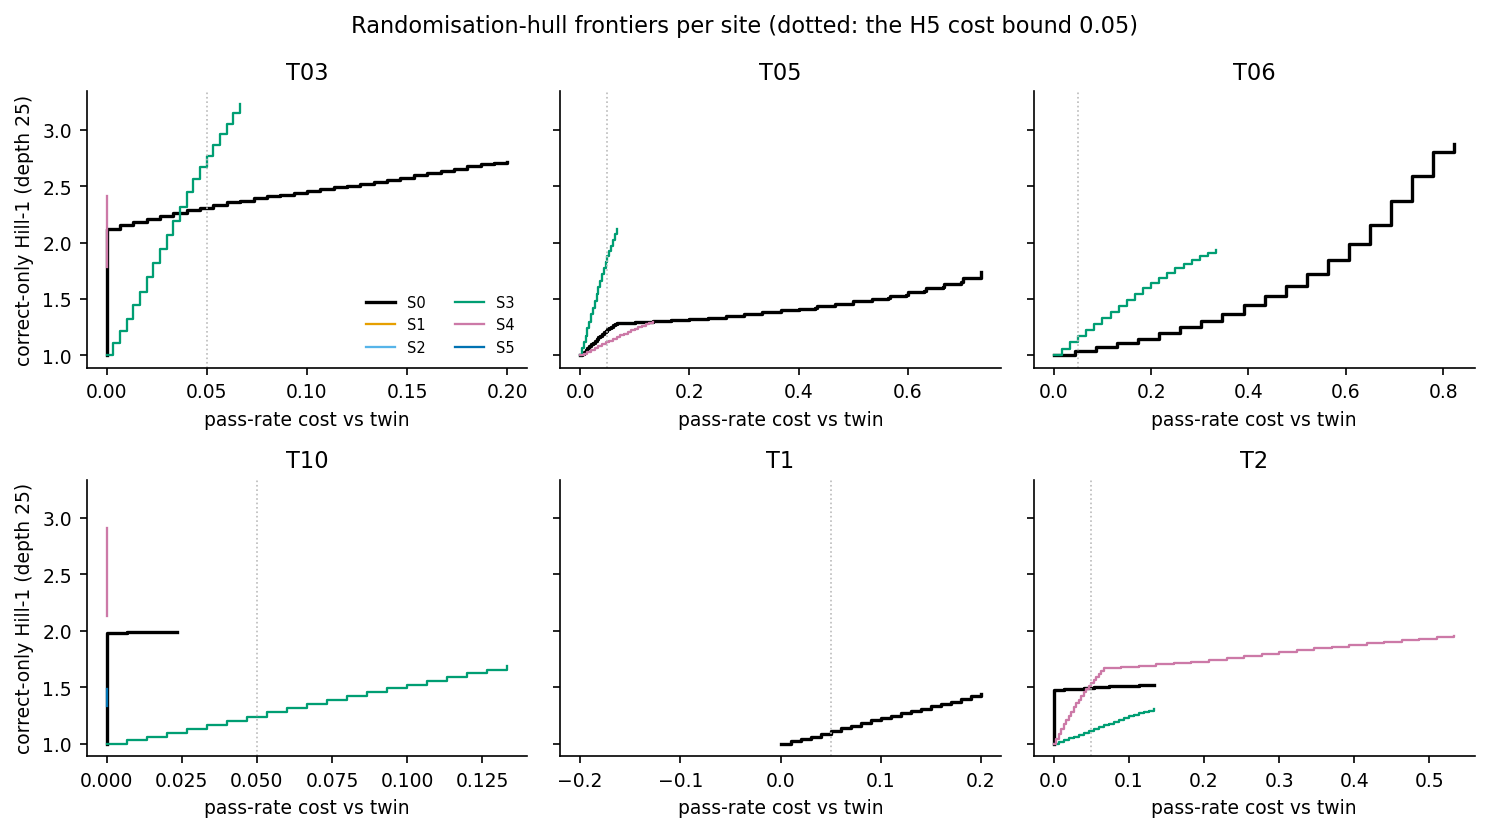

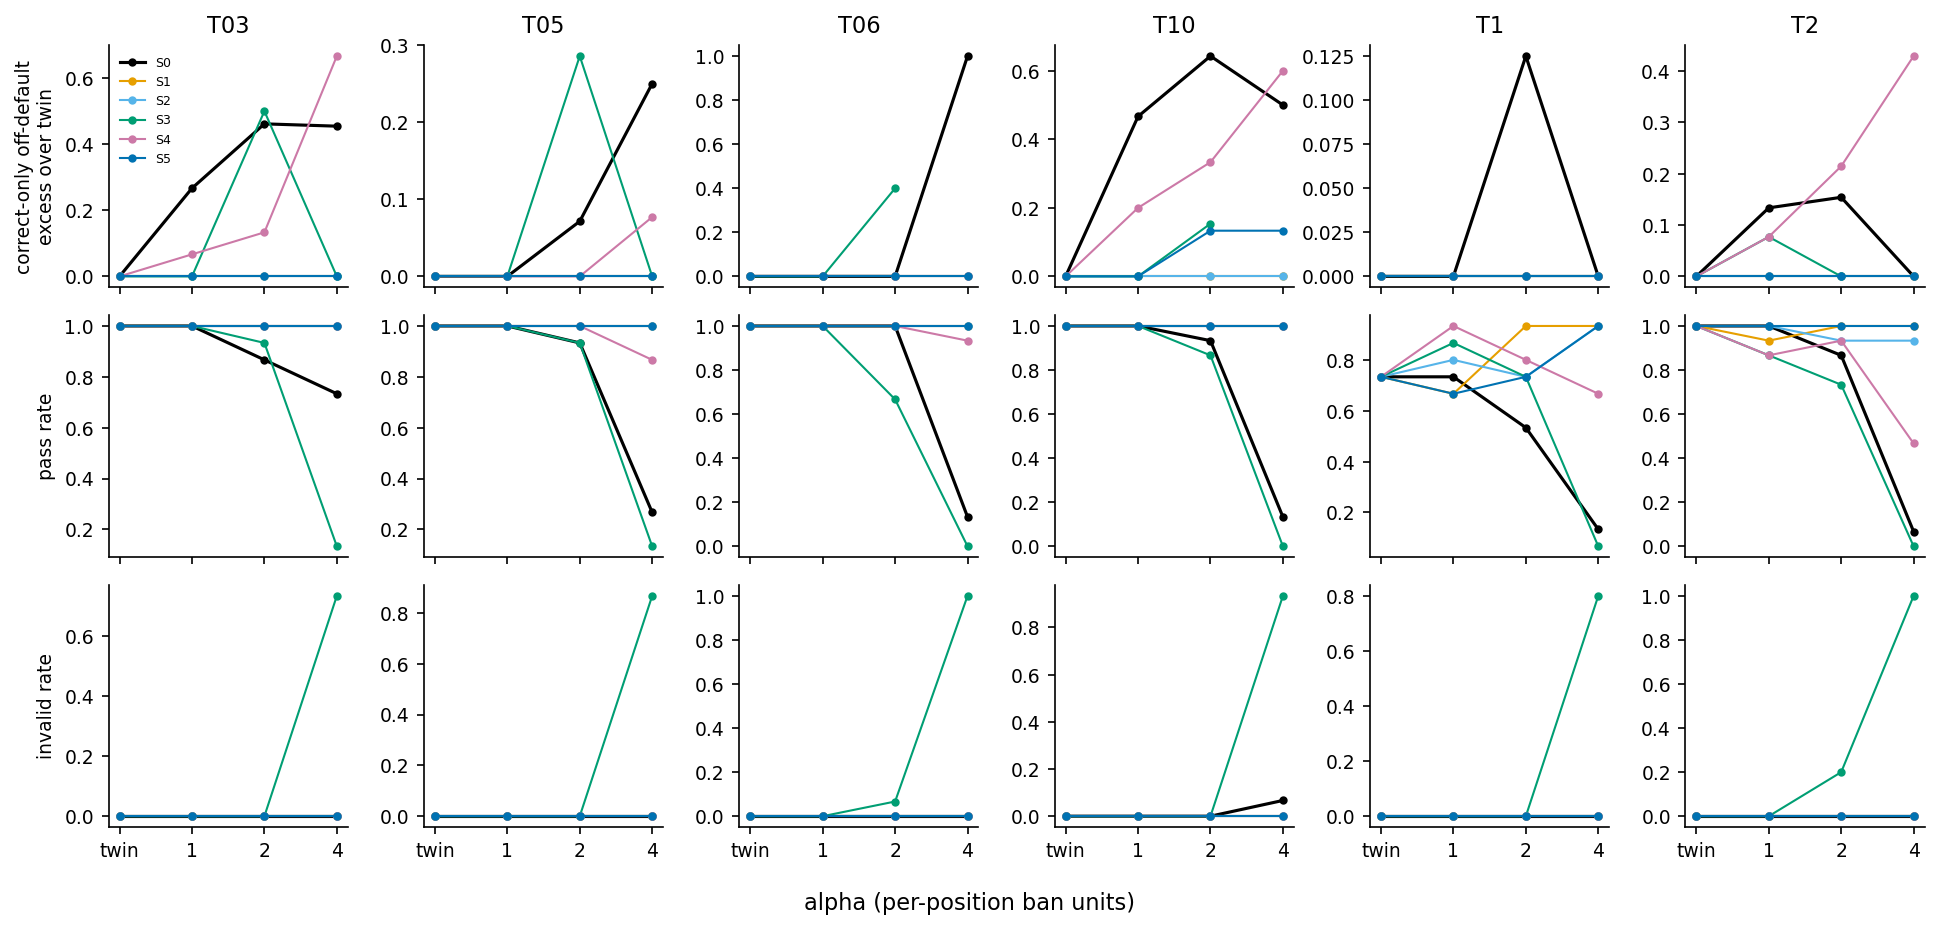

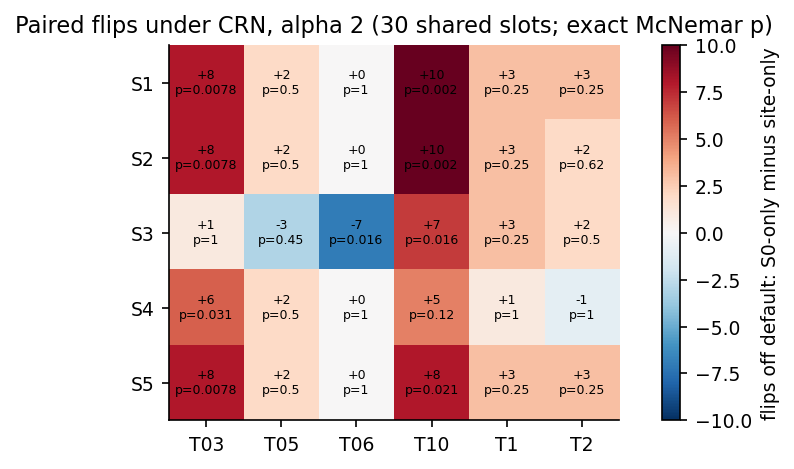

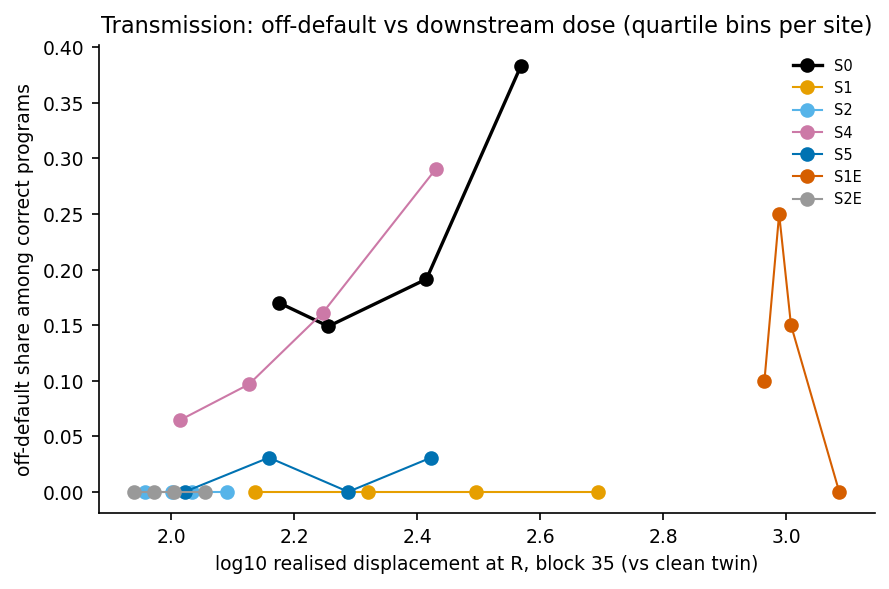

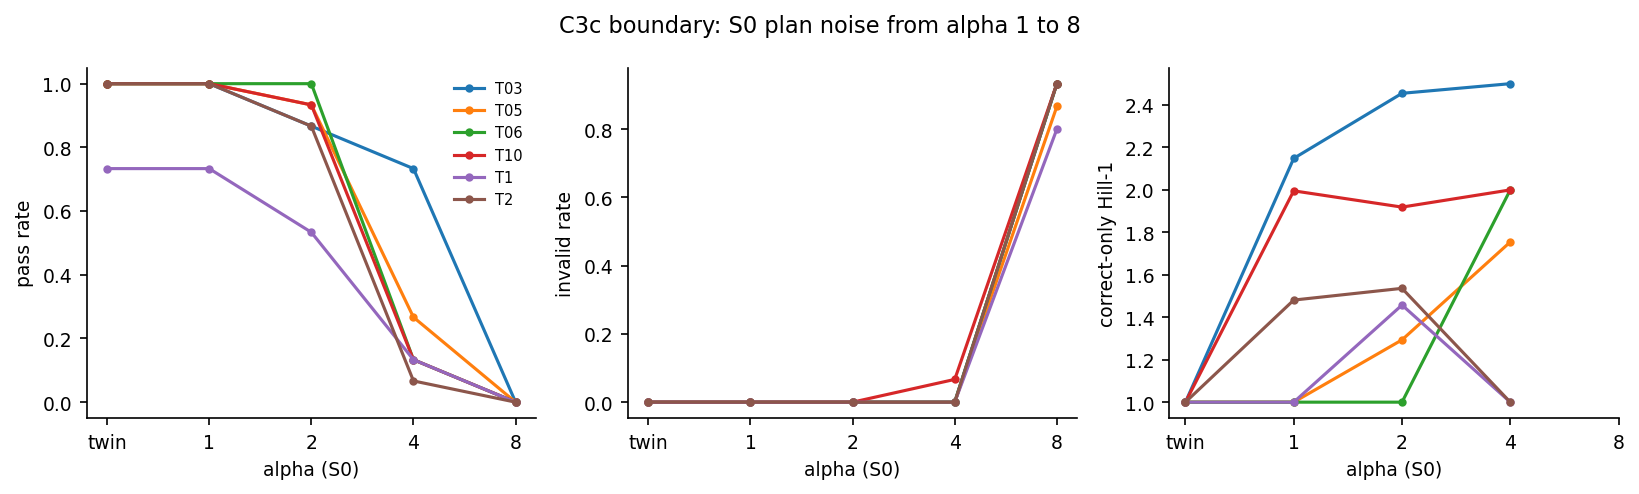

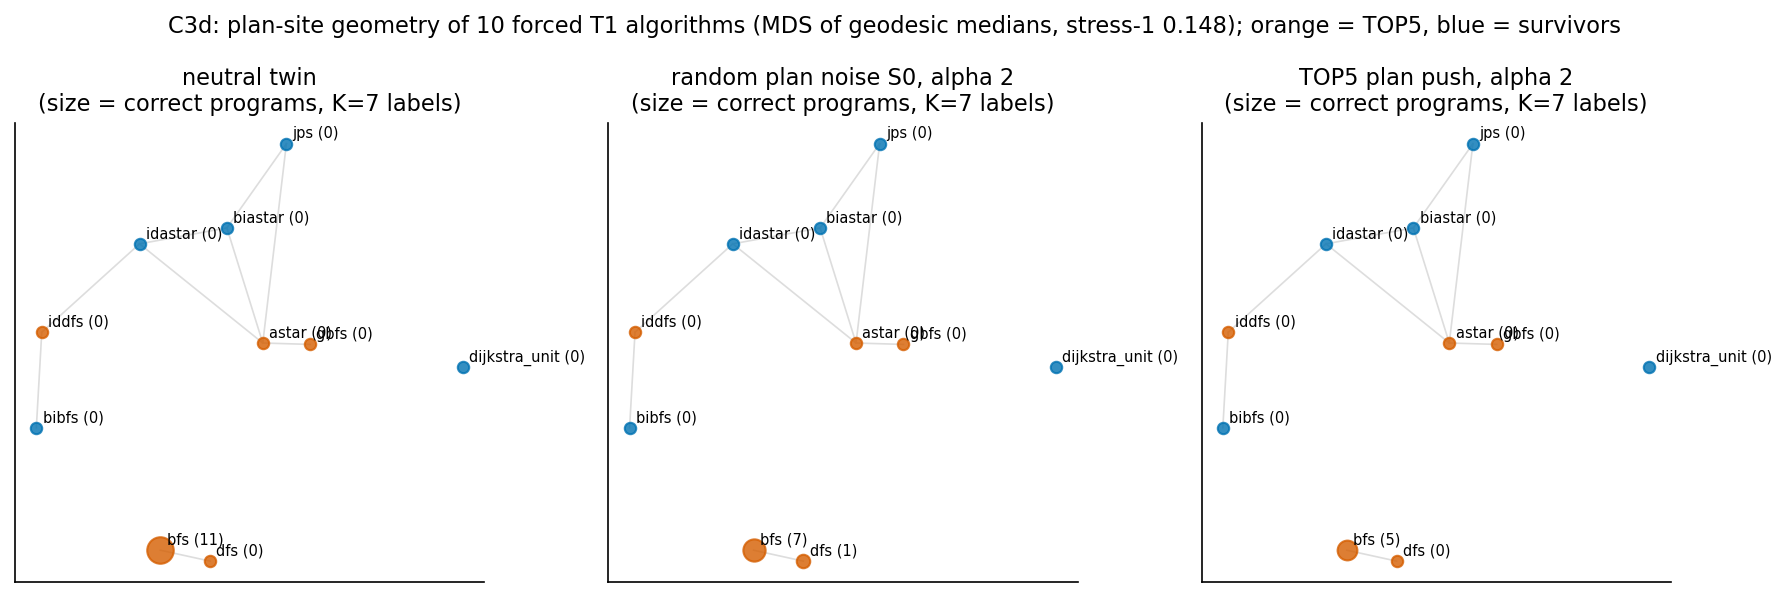

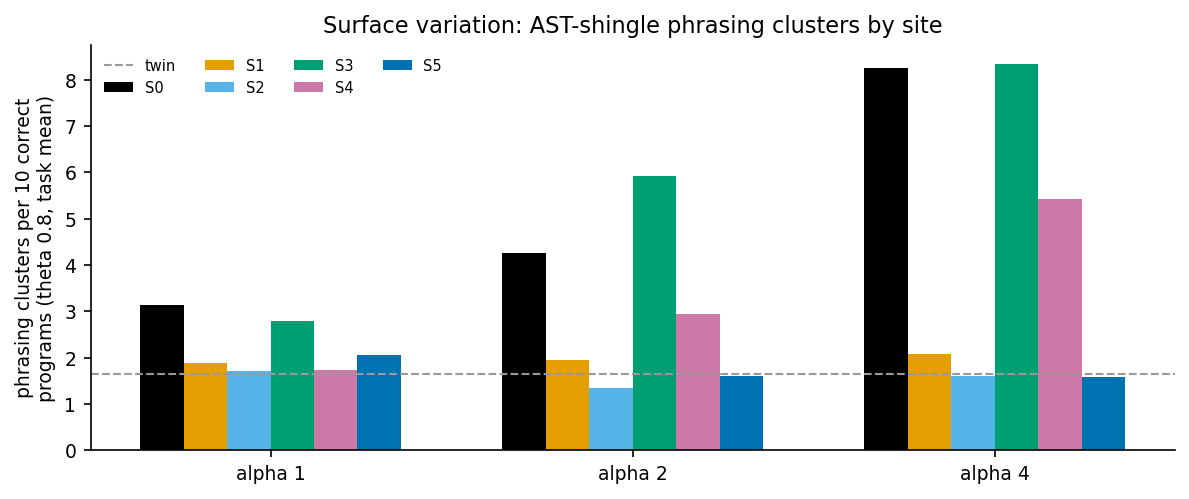

In [27]:
# ---- figures.main() (titles keep the full-run wording, e.g. "30 shared slots"; the demo uses 5 x len(DEMO_KS)) ----
for f in (fig1, fig2, fig3, fig4, fig5, fig6, fig7):
    try:
        f()
    except Exception as e:  # noqa: BLE001 - one broken figure must not stop the others
        print(f"{f.__name__} failed: {e}")

## 14. Summary and visualisation

The table puts the headline numbers of the demo subset next to the full run's. Rows marked "not re-run" come from stages that need the GPU, LLM judges or files outside the demo data.

The two plots then show:

1. **The activation space at the plan site.** The 300 forced T1 prompts in the first two principal components of their task-spec states (blocks 12-23), with the neutral twin prompts and the ban prompts projected into the same space.
2. **The dose convention.** The per-block ban unit for T03, and that unit relative to the twin's residual norm. This explains why S4 (blocks 0-11) gets a smaller *relative* push than S0 at the same alpha.
3. **Which algorithm the model writes.** The correct-program composition per site at alpha 2, with the default algorithm in grey.

In [28]:
# ---- Summary (notebook addition): headline numbers, demo subset vs full run ----
ref = data["metadata"]["full_run_reference"]


def _off(site: str) -> str:
    cor = [r for r in rows if r["site"] == site and r["alpha"] in GRID_ALPHAS and r["correct"]]
    return f"{sum(r['off'] for r in cor)}/{len(cor)}"


def _ind(tr: dict[str, Any]) -> str:
    d = tr.get("disp_R35", {})
    if "params" not in d:
        return "not fitted"
    return f"{d['params']['is_S0']:+.2f} [{d['ci95']['is_S0'][0]:+.2f}, {d['ci95']['is_S0'][1]:+.2f}]"


_a8 = [x["pass"] for t in TASKS for x in bnd["per_task"][t]["curve"] if x["alpha"] == 8.0]
_av = [c3["by_arm"].get(f"TOP5_a{a}", {}).get("k7", {}).get("avoidance") for a in (1, 2)]
_rel = {s: [ref["units_summary"][t][k]["rel"] for t in TASKS] for s, k in (("S0", "S0_blocks12_23"),
                                                                           ("S4", "S4_blocks0_11"))}
summary_rows = [
    ("programs analysed", f"{len(rows)} (k in {DEMO_KS})", "4,510"),
    ("C1-site verdict", f"{c1['verdict']} (S0 best {c1['count_S0_best']}/{c1['n_tasks']}, p={c1['raw_p_binom']:.3f})",
     f"{ref['c1_site']['verdict']} (S0 best {ref['c1_site']['count_S0_best']}/6, p={ref['c1_site']['raw_p_binom']:.3f})"),
    ("best site per task", " ".join(f"{t}:{b}" for t, b in c1["best_site"].items()),
     " ".join(f"{t}:{b}" for t, b in ref["c1_site"]["best_site"].items())),
    ("correct off-default programs S0 (alpha 1-4)", _off("S0"), "-"),
    ("correct off-default programs S1 / S2 / S5", f"{_off('S1')} / {_off('S2')} / {_off('S5')}",
     "0/526 / 0/527 / 6/521"),  # full-run counts: README / results/rederive_headlines.json
    ("transmission: S0 indicator at matched displacement", _ind(trans), _ind(ref["transmission"])),
    ("max pass rate at alpha 8", f"{max(_a8):.2f}" if _a8 else "n/a", "0.00"),
    ("TOP5 plan push: avoidance at alpha 1 / 2", " / ".join("n/a" if v is None else f"{v:.2f}" for v in _av),
     "0.00 / 0.00"),
    ("novel algorithms among correct programs (audit, not re-run)", "-",
     f"{ref['novelty_audit']['n_novel_confirmed']} of {ref['novelty_audit']['n_correct_programs_all_arms']}"),
    ("engine check: programs identical to exp17 screen (not re-run)", "-",
     f"T03 {ref['engine_check']['T03']['per_slot_identical_code']:.2f}, T2 {ref['engine_check']['T2']['per_slot_identical_code']:.2f}"),
    ("relative ban unit S0 vs S4 (units, not re-run)", "-",
     f"S0 {100 * min(_rel['S0']):.1f}-{100 * max(_rel['S0']):.1f}% vs S4 {100 * min(_rel['S4']):.1f}-{100 * max(_rel['S4']):.1f}%"),
]
print(pd.DataFrame(summary_rows, columns=["", "demo subset", "full run"]).to_string(index=False))

                                                                                          demo subset                                full run
                                            programs analysed                   2025 (k in [0, 1, 2])                                   4,510
                                              C1-site verdict          PARTIAL (S0 best 1/6, p=0.665)          PARTIAL (S0 best 3/6, p=0.062)
                                           best site per task T03:S3 T05:S3 T06:S3 T10:S4 T1:S0 T2:S4 T03:S0 T05:S3 T06:S3 T10:S4 T1:S0 T2:S0
                  correct off-default programs S0 (alpha 1-4)                                  41/185                                       -
                    correct off-default programs S1 / S2 / S5                   0/262 / 0/260 / 4/260                   0/526 / 0/527 / 6/521
           transmission: S0 indicator at matched displacement                    +1.94 [+1.44, +2.43]                    +2.15 [+1.79, +2.51]
      

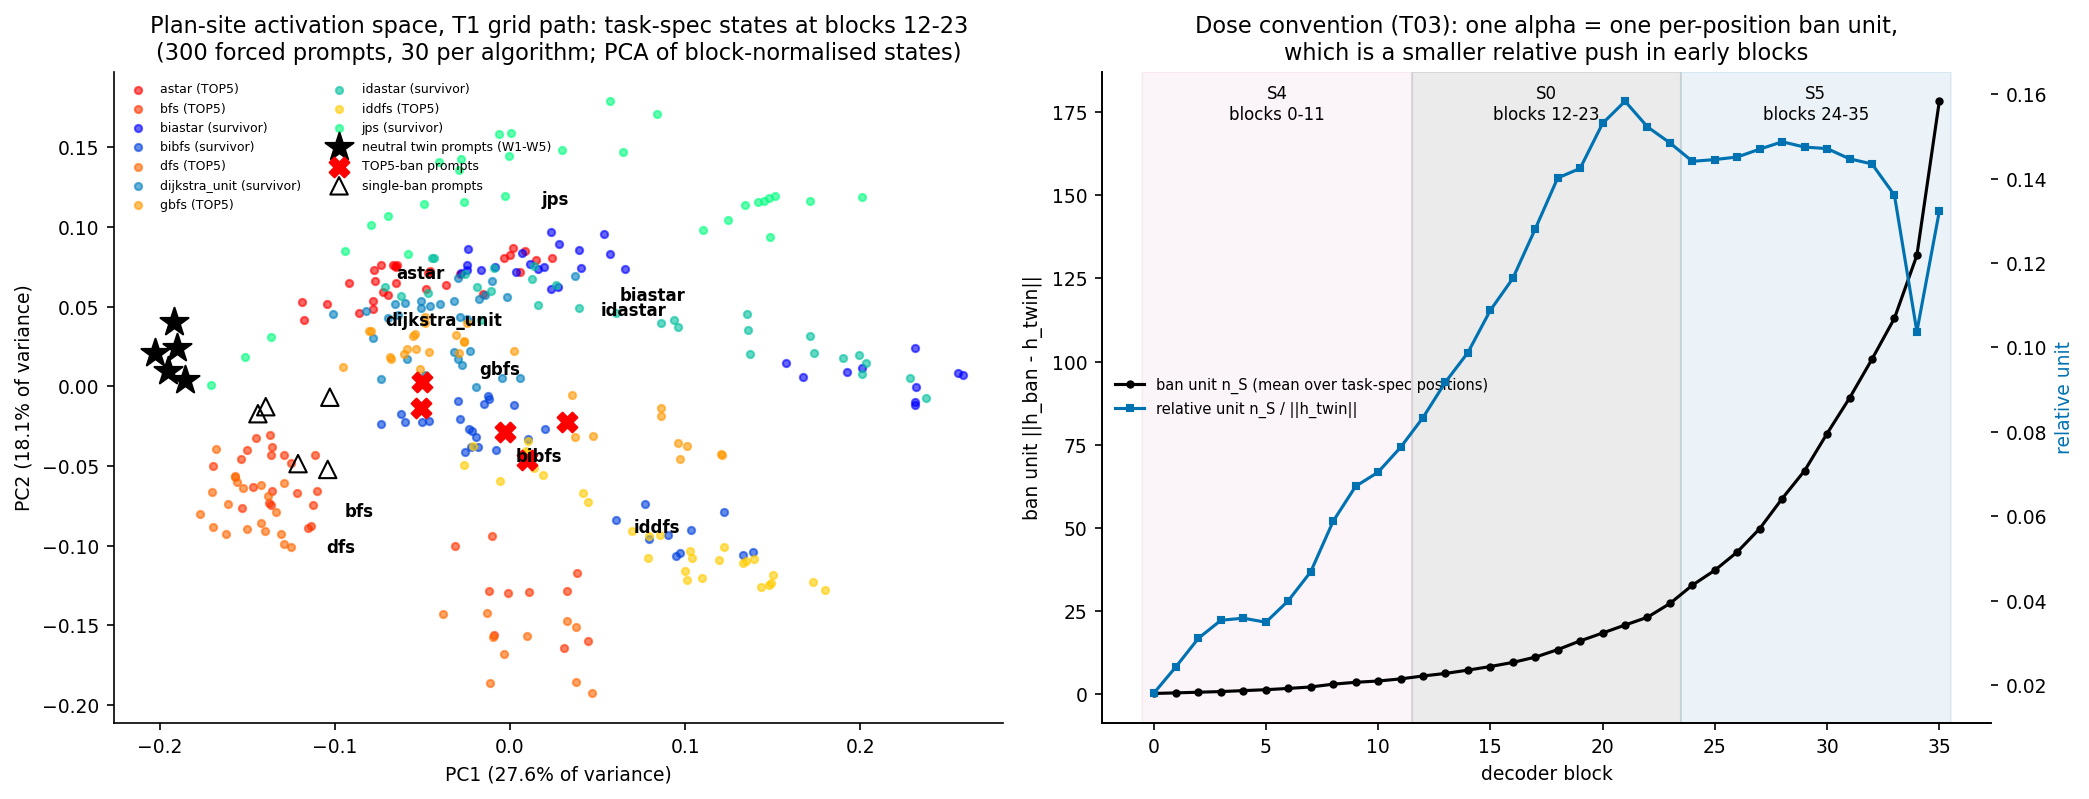

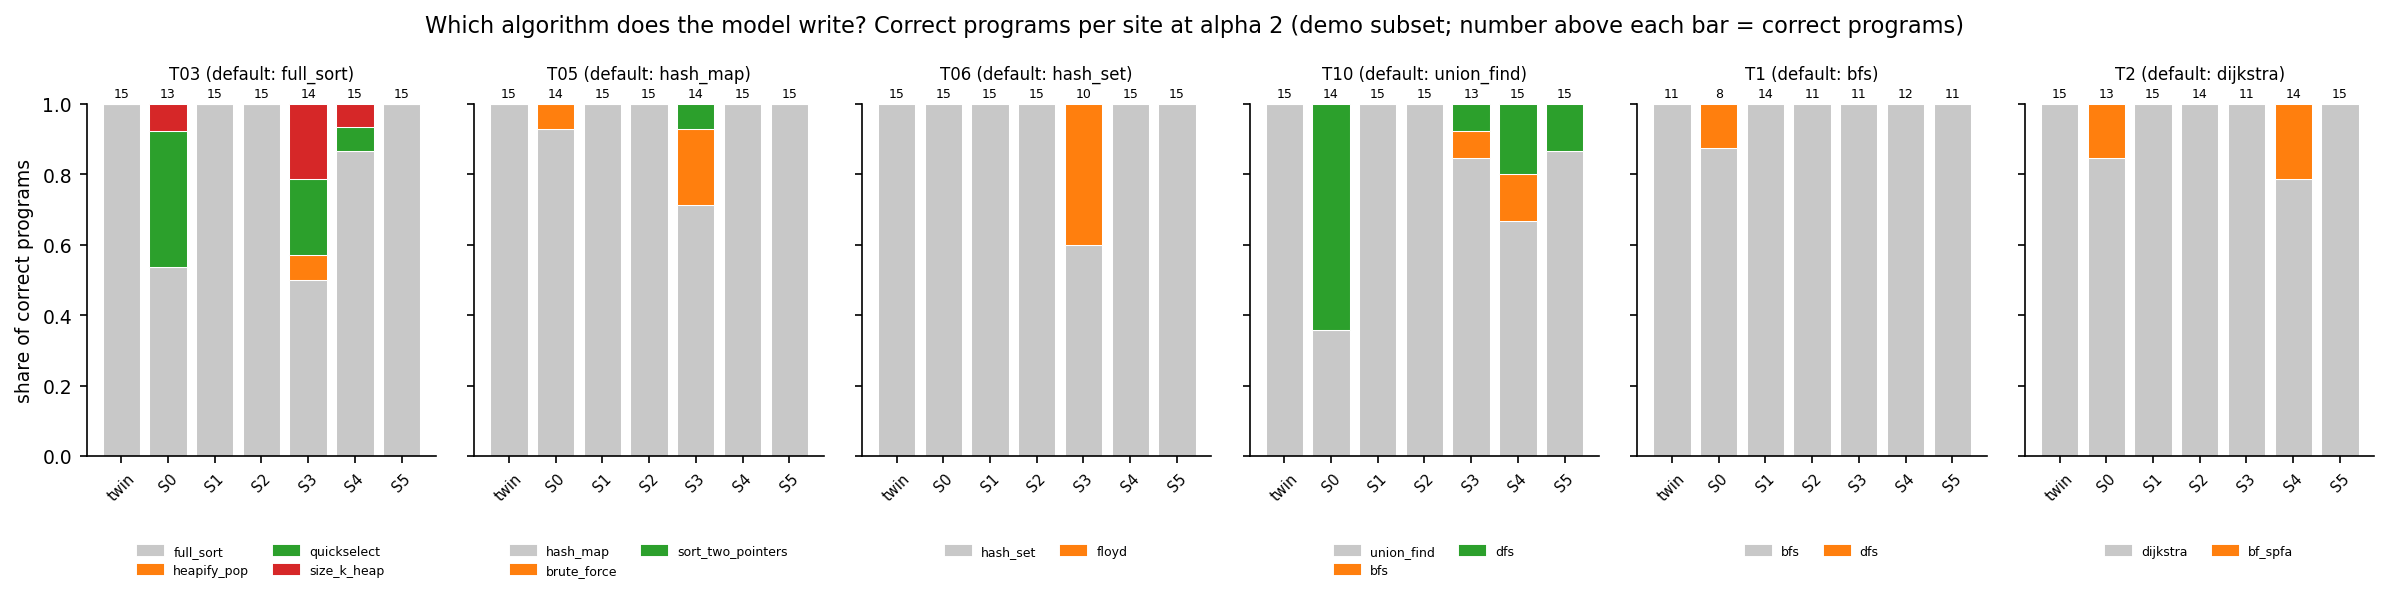

In [29]:
# ---- Visualization (notebook addition) ----
from matplotlib.patches import Patch

# (1) activation space at the plan site + (2) the dose convention
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4))
ax = axs[0]
pcs, algs_arr, ev = PLAN_GEOMETRY_T1["pc"], PLAN_GEOMETRY_T1["algs"], PLAN_GEOMETRY_T1["explained"]
alg_names = sorted(set(algs_arr.tolist()))
warm = iter(plt.cm.autumn(np.linspace(0.0, 0.8, len(TOP5))))
cool = iter(plt.cm.winter(np.linspace(0.0, 1.0, len(alg_names) - len(TOP5))))
acol = {a: next(warm) if a in TOP5 else next(cool) for a in alg_names}
for a in alg_names:
    m = algs_arr == a
    ax.scatter(pcs[m, 0], pcs[m, 1], s=12, color=acol[a], alpha=0.6,
               label=a + (" (TOP5)" if a in TOP5 else " (survivor)"))
    ax.annotate(a, (pcs[m, 0].mean(), pcs[m, 1].mean()), fontsize=8, weight="bold", ha="center")
ax.scatter(*PLAN_GEOMETRY_T1["pc_twin"][:, :2].T, marker="*", s=200, color="black", label="neutral twin prompts (W1-W5)")
ax.scatter(*PLAN_GEOMETRY_T1["pc_top5ban"][:, :2].T, marker="X", s=90, color="red", label="TOP5-ban prompts")
ax.scatter(*PLAN_GEOMETRY_T1["pc_ban1"][:, :2].T, marker="^", s=70, facecolor="none", edgecolor="black",
           label="single-ban prompts")
ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}% of variance)")
ax.set_title("Plan-site activation space, T1 grid path: task-spec states at blocks 12-23\n"
             "(300 forced prompts, 30 per algorithm; PCA of block-normalised states)")
ax.legend(fontsize=6, frameon=False, ncol=2, loc="best")

ax = axs[1]
nS, tn = UNITS_T03["nS"], UNITS_T03["twin_norm_S"]
blocks = np.arange(nS.shape[0])
l1 = ax.plot(blocks, nS.mean(1), color="black", marker="o", ms=3, label="ban unit n_S (mean over task-spec positions)")
ax.set_xlabel("decoder block")
ax.set_ylabel("ban unit ||h_ban - h_twin||")
ax2 = ax.twinx()
l2 = ax2.plot(blocks, (nS / tn).mean(1), color="#0072B2", marker="s", ms=3, label="relative unit n_S / ||h_twin||")
ax2.set_ylabel("relative unit", color="#0072B2")
for (lo, hi), s in (((0, 11), "S4"), ((12, 23), "S0"), ((24, 35), "S5")):
    ax.axvspan(lo - 0.5, hi + 0.5, color=COL[s], alpha=0.08)
    ax.text((lo + hi) / 2, 0.98, f"{s}\nblocks {lo}-{hi}", ha="center", va="top", fontsize=8,
            transform=ax.get_xaxis_transform())
ax.legend(l1 + l2, [h.get_label() for h in l1 + l2], fontsize=7, frameon=False, loc="center left")
ax.set_title("Dose convention (T03): one alpha = one per-position ban unit,\nwhich is a smaller relative push in early blocks")
fig.tight_layout()
plt.show()

# (3) which algorithm does the model write? correct-program composition per site at alpha 2
fig, axs = plt.subplots(1, len(TASKS), figsize=(16, 4.2), sharey=True)
for ax, t in zip(axs, TASKS):
    arms = [("twin", cells.get(f"{t}|TWIN|0"))] + [(s, cells.get(f"{t}|{s}|2")) for s in SITES]
    labs = sorted({l for _, c in arms if c for l in c["correct_composition"]}, key=lambda l: (l != DEFAULT[t], l))
    pal = {l: "#c8c8c8" if l == DEFAULT[t] else plt.cm.tab10(i % 10) for i, l in enumerate(labs)}
    for j, (name, c) in enumerate(arms):
        comp = (c or {}).get("correct_composition", {})
        tot, bottom = sum(comp.values()), 0.0
        for l in labs:
            v = comp.get(l, 0) / tot if tot else 0.0
            ax.bar(j, v, bottom=bottom, color=pal[l], edgecolor="white", lw=0.5)
            bottom += v
        ax.text(j, 1.01, str(tot), ha="center", va="bottom", fontsize=6)
    ax.set_xticks(range(len(arms)), [a for a, _ in arms], rotation=45, fontsize=7)
    ax.set_title(f"{t} (default: {DEFAULT[t]})", fontsize=8, pad=12)
    ax.legend(handles=[Patch(color=pal[l], label=l) for l in labs], fontsize=6, frameon=False,
              loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
axs[0].set_ylabel("share of correct programs")
fig.suptitle("Which algorithm does the model write? Correct programs per site at alpha 2 "
             "(demo subset; number above each bar = correct programs)")
fig.tight_layout()
plt.show()

## Takeaways

- **The site matters, not just the amount of noise.** The same random direction, with the same token uniforms, changes which correct algorithm Qwen3-8B writes only when it is written into the **task-specification states at early-to-middle blocks** (S0, and S4 at higher doses). Written at the read position (S1) or on the condition sentence (S2), it never changes the algorithm. On the task spec at late blocks (S5) it almost never does. Those sites' outputs are often byte-identical to the twin's.
- **It is not a matter of push size downstream.** S1 moves the state at block 35 as far as S0 does, yet S0 keeps a large off-default advantage at matched downstream displacement. The effect is tied to the site, not to how far the perturbation travels.
- **There is no free lunch beyond the catalogue.** More noise first trades passes for diversity, then erases the task: at alpha 8 the pass rate is 0. Every correct "different" program in the full run was a known algorithm or one of its variants (0 novel among 3,555). Pushing the plan states away from the five most common path-search algorithms never moved T1 off BFS.
- **Ideas vs phrasings.** Generated-token noise (S3) mostly changes the *phrasing*: more AST-shingle clusters per idea (fig 7). It also breaks programs first at high doses.

**Limits.** These results come from one model (Qwen3-8B in FP8) on six memorised tasks. The doses are expressed in ban units, so there is no convention-free dose (see the dose-convention plot). N = 30 per cell in the full run, and N ≤ 15 in this demo, separates inert sites from live ones but cannot rank two live sites. To get closer to the paper's numbers, raise the config values (`DEMO_KS = [0, 1, 2]`, `BOOT_B` towards 2000).